ΖΟΡΜΠΑ ΕΛΕΝΗ - 1115202200049 

ΒΑΣΙΛΙΚΗ ΚΑΛΑΝΤΖΗ - 1115202200057 

ΠΑΝΑΓΙΩΤΑ ΚΑΤΡΑ - 1115202200067

We have used Kaggle in this project and have also downloaded fasttext-crawl-300d-2m model in kaggle(https://www.kaggle.com/datasets/yekenot/fasttext-crawl-300d-2m), because we came across some difficulties downloading the Fast Text model with the gensim downloader.

In [2]:
!pip install --upgrade  datasets --quiet
!pip install transformers --quiet
!pip install negspacy --quiet
!pip install emoji --quiet
!pip install --upgrade nltk --quiet
!pip install gensim
!pip install contractions --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 4.2 MB/s eta 0:00:00a 0:00:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cesium 0.12.4 requires numpy<3.0,>=2.0, but you have numpy 1.26.4 which is incompatible.
bigframes 1.42.0 requires rich<14,>=12.4.4, but you have rich 14.0.0 which is incompatible.
torch 2.6.0+cu124 requires nvidia-cublas-cu12==12.4.5.8; platform_system == "Linux" and platform_machine == "x86_64", but you have nvidia-cublas-cu12 12.9.0.13 which is incompatible.
torch 2.6.0+cu124 requires nvidia-cudnn-cu12==9.1.0.70; platform_system == "Linux" and platform_machine == "x86_64", but you have nvidia-cudnn-cu12 9.3.0.75 which is incompatible.
torch 2.6.0+cu124 requires nvidia-cufft-cu12==11.2.1.3; platform_system == "Linux" and platform_machine == "x86_64", but you have nvidia-cufft-cu12 11.4.0.6 which is incompatible.
torch 2.6.0+

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re
import string
import emoji
import spacy
import nltk
nltk.download('punkt_tab')
import contractions 

import zipfile

from nltk.tokenize import word_tokenize
from datasets import load_dataset
from wordcloud import WordCloud
from google.colab import files
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from transformers import pipeline
from tqdm import tqdm
from negspacy.negation import Negex
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning, module="sklearn.cluster._kmeans")
warnings.filterwarnings("ignore", category=FutureWarning, module="seaborn")



[nltk_data] Downloading package punkt_tab to /usr/share/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
2025-06-27 09:45:53.646666: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1751017553.890474      35 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1751017553.961849      35 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [57]:

import gensim.downloader as api
# Load pre-trained Word2Vec (Google News vectors or similar)
w2v_model = api.load('glove-wiki-gigaword-100')  # ~100MB, fast

In [4]:
# Define categories and their dataset configs
category_dict = {
    "All_Beauty": {
        "review": "raw_review_All_Beauty",
        "meta": "raw_meta_All_Beauty"
    },
    "Digital_Music": {
        "review": "raw_review_Digital_Music",
        "meta": "raw_meta_Digital_Music"
    },
    "Video_Games": {
        "review": "raw_review_Video_Games",
        "meta": "raw_meta_Video_Games"
    },
    "Handmade_Products": {
        "review": "raw_review_Handmade_Products",
        "meta": "raw_meta_Handmade_Products"
    },
    "Health_and_Personal_Care": {
        "review": "raw_review_Health_and_Personal_Care",
        "meta": "raw_meta_Health_and_Personal_Care"
    }
}

#  Download and save reviews and metadata for each category
for category, config in category_dict.items():

    # Load reviews
    reviews = load_dataset("McAuley-Lab/Amazon-Reviews-2023", config["review"],
                           split="full", trust_remote_code=True)
    reviews_iter = iter(reviews)
    review_samples = [next(reviews_iter) for _ in range(50000)]  # 30k reviews

    df_reviews = pd.DataFrame(review_samples)
    df_reviews.to_csv(f"{category.lower()}_reviews.csv", index=False)


    # Load metadata
    meta = load_dataset("McAuley-Lab/Amazon-Reviews-2023", config["meta"],
                        split="full", trust_remote_code=True)
    meta_iter = iter(meta)
    meta_samples = [next(meta_iter) for _ in range(50000)] # 30k reviews

    df_meta = pd.DataFrame(meta_samples)
    df_meta.to_csv(f"{category.lower()}_meta.csv", index=False)


#Show all files saved in the current directory
print("\n Files in working directory:")
print(os.listdir())


README.md: 0.00B [00:00, ?B/s]

Amazon-Reviews-2023.py: 0.00B [00:00, ?B/s]

All_Beauty.jsonl:   0%|          | 0.00/327M [00:00<?, ?B/s]

Generating full split: 0 examples [00:00, ? examples/s]

meta_All_Beauty.jsonl:   0%|          | 0.00/213M [00:00<?, ?B/s]

Generating full split:   0%|          | 0/112590 [00:00<?, ? examples/s]

... (13 outputs left out)

Generating full split: 0 examples [00:00, ? examples/s]

meta_Health_and_Personal_Care.jsonl:   0%|          | 0.00/118M [00:00<?, ?B/s]

Generating full split: 0 examples [00:00, ? examples/s]


 Files in working directory:
['video_games_meta.csv', '.virtual_documents', 'digital_music_reviews.csv', 'health_and_personal_care_reviews.csv', 'handmade_products_meta.csv', 'all_beauty_reviews.csv', 'handmade_products_reviews.csv', 'video_games_reviews.csv', 'health_and_personal_care_meta.csv', 'digital_music_meta.csv', 'all_beauty_meta.csv']


In [5]:

#  Safely cleans missing values in a DataFrame
# - Numerical columns: fill with a placeholder -1 to allow filtering later
# - Object columns: fill with unknown

def clean_missing_values(df):

    df_cleaned = df.copy()

    for col in df_cleaned.columns:
        if df_cleaned[col].isnull().sum() > 0:
            if pd.api.types.is_numeric_dtype(df_cleaned[col]):
                df_cleaned[col] = pd.to_numeric(df_cleaned[col], errors='coerce')
                df_cleaned[col] = df_cleaned[col].fillna(-1)  # Use -1 as missing flag for numeric
            else:
                df_cleaned[col] = df_cleaned[col].fillna("unknown")  # Use 'unknown' as missing flag for objects

    return df_cleaned

In [7]:
from sklearn.preprocessing import StandardScaler

# Normalizes the 'price' column in the DataFrame using Min-Max scaling,
# ignoring rows where price is missing (-1).

def normalize_prices(df):
    df = df.copy()
    df['price'] = pd.to_numeric(df['price'], errors='coerce')


    # Apply normalization only to valid price values
    valid_prices = df['price'] >= 0
    # scaler = MinMaxScaler()
    scaler = StandardScaler()
    df.loc[valid_prices, 'normalized_price'] = scaler.fit_transform(df.loc[valid_prices, ['price']])

    return df

# Normalizes the 'rating' column using Min-Max scaling (0 to 1),
# ignoring missing or invalid values (e.g., -1)
def normalize_ratings(df):

    df = df.copy()
    df['rating'] = pd.to_numeric(df['rating'], errors='coerce')

    # df['rating_original'] = df['rating']

    valid_ratings = df['rating'] >= 0
    # scaler = MinMaxScaler()
    scaler = StandardScaler()
    df.loc[valid_ratings, 'normalized_rating'] = scaler.fit_transform(df.loc[valid_ratings, ['rating']])

    return df


In [8]:
nlp = spacy.load("en_core_web_sm")

NEGATION_WORDS = {"no", "not", "none", "neither", "nor", "never"}
NEGATION_PHRASES = {
    "not at all": "not_at_all",
    "not only": "not_only"
}

def handle_negation(text):
    """Process negation in text by marking negated words"""
    # Process phrases first
    for phrase, replacement in NEGATION_PHRASES.items():
        text = text.replace(phrase, replacement)

    words = word_tokenize(text.lower())
    processed_words = []
    negated = False

    for word in words:
        if word in NEGATION_WORDS:
            negated = True
            processed_words.append("[NEG]")  # Keep negation token
        elif negated:
            processed_words.append(f"not_{word}")
            negated = False
        else:
            processed_words.append(word)

    return " ".join(processed_words)

def replace_emojis(text):
    """Convert emojis to descriptive text and map common ones to compact sentiment tokens."""
    # Convert emojis to descriptive form (e.g., 😍 → [smiling_face_with_heart_eyes])
    text = emoji.demojize(text, delimiters=(" [", "] "))

    EMOJI_CATEGORY_MAP = {
        "smiling_face_with_heart_eyes": "[love]",
        "red_heart": "[love]",
        "sparkling_heart": "[love]",
        "face_blowing_a_kiss": "[love]",
        "two_hearts": "[love]",
        "heart_with_arrow": "[love]",
        "blue_heart": "[love]",
        "green_heart": "[love]",
        "yellow_heart": "[love]",
        "thumbs_up": "[positive]",
        "clapping_hands": "[positive]",
        "grinning_face": "[happy]",
        "face_with_tears_of_joy": "[laugh]",
        "rolling_on_the_floor_laughing": "[laugh]",
        "smiling_face_with_smiling_eyes": "[happy]",
        "crying_face": "[sad]",
        "loudly_crying_face": "[sad]",
        "angry_face": "[angry]",
        "pouting_face": "[angry]",
        "fire": "[intense]",
        "face_screaming_in_fear": "[shock]",
        "star_struck": "[wow]",
        "face_with_raised_eyebrow": "[skeptical]",
        "winking_face": "[wink]"
    }


    # map common descriptive emoji tokens to simplified sentiment tokens
    for full, simplified in EMOJI_CATEGORY_MAP.items():
        text = text.replace(f"[{full}]", simplified)

    return text

def replace_emoticons(text):
    """
    Replaces common emoticons with text tokens preserving sentiment.
    Improves accuracy by maintaining emotional context.
    """
    # Emoticon-to-text mapping dictionary
    EMOTICON_MAP = {
        # Positive
        ":‑)": " [happy] ", ":)": " [happy] ", ":-]": " [happy] ",
        ":]": " [happy] ", ":-3": " [happy] ", ":3": " [happy] ",
        "=]": " [happy] ", "=)": " [happy] ", ":)": " [happy] ",
        "=D": " [happy]", '<3': ' [love] ',

        # Negative
        "=(": " [sad] ", ":(": " [sad] ", ":-c": " [sad] ",
        ":-[": " [sad] ", ":[": " [sad] ", ":{": " [sad] ",
    }

    # Replace emoticons
    for emoticon, replacement in EMOTICON_MAP.items():
        text = text.replace(emoticon, replacement)

    # Handle repeated characters ("Heyyyy" -> "Heyy")
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    # Handle repeated punctuation
    text = re.sub(r"([!?.,])\1{1,}", r"\1", text)

    # Clean whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text


def remove_unicode(text):
    """Convert to ASCII and clean special characters"""
    text = text.encode('ascii', 'ignore').decode('ascii')
    # Additional cleaning
    text = re.sub(r"[^\w\s.,!?;]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def preprocess_text(text):
    """Main text preprocessing pipeline"""
    text = remove_unicode(text)
    text = text.lower()
    text = replace_emoticons(text)
    text = replace_emojis(text)

    # Remove urls
    text = re.sub(r"http\S+|www\.\S+", "", text)

    # Remove numbers
    text = re.sub(r'\d+', '', text)

    # Replace emails
    text = re.sub(r"\S+@\S+", 'mail', text)  
    # Expand contractions
    text = contractions.fix(text)  
    # Handle negation
    text = handle_negation(text)

    return text

In [9]:
# Dictionary to store cleaned DataFrames per category
cleaned_data = {}

for category in category_dict.keys():
    print(f"\n Cleaning category: {category.upper()}")


    filename = category.lower()
    df_reviews = pd.read_csv(f"{filename}_reviews.csv")
    df_meta = pd.read_csv(f"{filename}_meta.csv")


    # Apply cleaning
    df_clean_reviews = clean_missing_values(df_reviews)
    df_clean_meta = clean_missing_values(df_meta)

    #Normalize prices
    df_clean_meta = normalize_prices(df_clean_meta)
    df_clean_reviews = normalize_ratings(df_clean_reviews)


    # Text preprocessing
    df_clean_reviews['text'] = df_clean_reviews['text'].apply(preprocess_text)

    # Store cleaned data for further processing
    cleaned_data[category] = {
        "reviews": df_clean_reviews,
        "meta": df_clean_meta
    }


 Cleaning category: ALL_BEAUTY

 Cleaning category: DIGITAL_MUSIC

 Cleaning category: VIDEO_GAMES

 Cleaning category: HANDMADE_PRODUCTS

 Cleaning category: HEALTH_AND_PERSONAL_CARE


Plotting Distribution of Product Ratings for Each Category

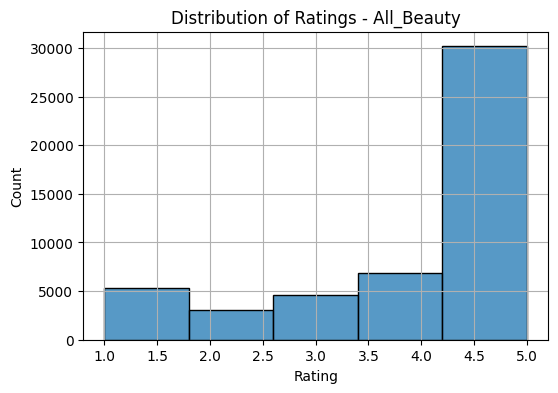

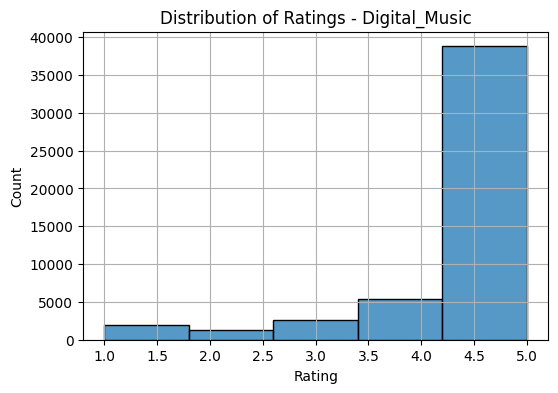

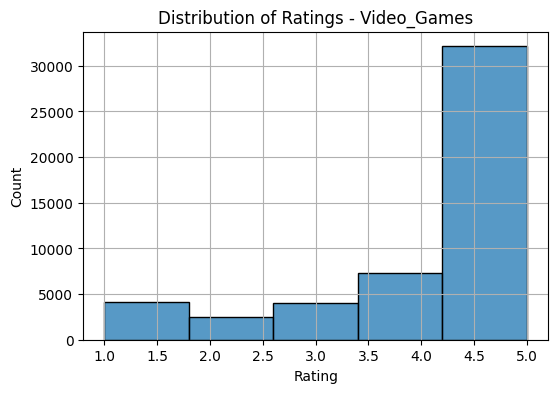

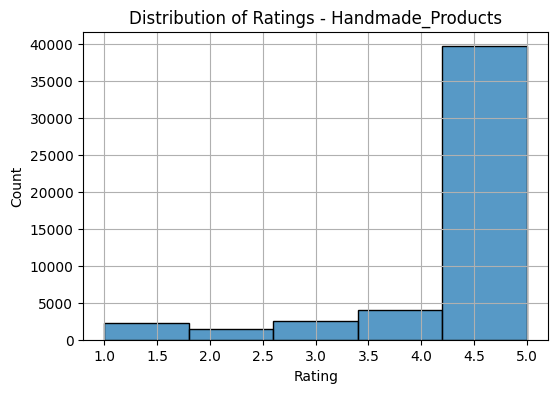

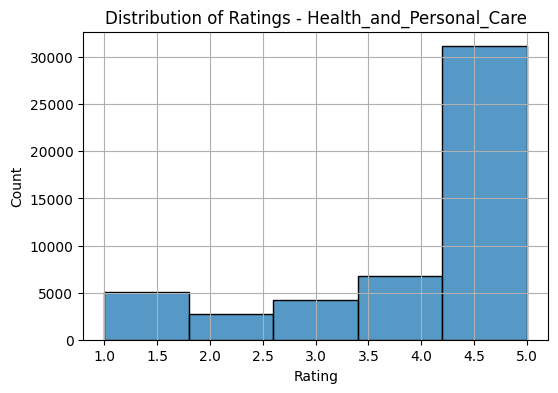

In [59]:
for category, data in cleaned_data.items():
    df = data['reviews']
    plt.figure(figsize=(6, 4))
    sns.histplot(df['rating'], bins=5, kde=False)
    plt.title(f'Distribution of Ratings - {category}')
    plt.xlabel('Rating')
    plt.ylabel('Count')
    plt.grid(True)
    plt.show()

Identifying Low-Rated High-Review Products and Visualizing Common Keywords with Word Clouds


All_Beauty - Products with Many Reviews but Low Ratings:
      product_id  avg_rating  review_count
43    B00011QUDE    3.000000            32
1151  B005FMUBLG    2.769231            13
4810  B01195J43I    2.739130            23
5154  B0150VWF5G    3.000000            12
6282  B01CE23EEA    3.000000            12


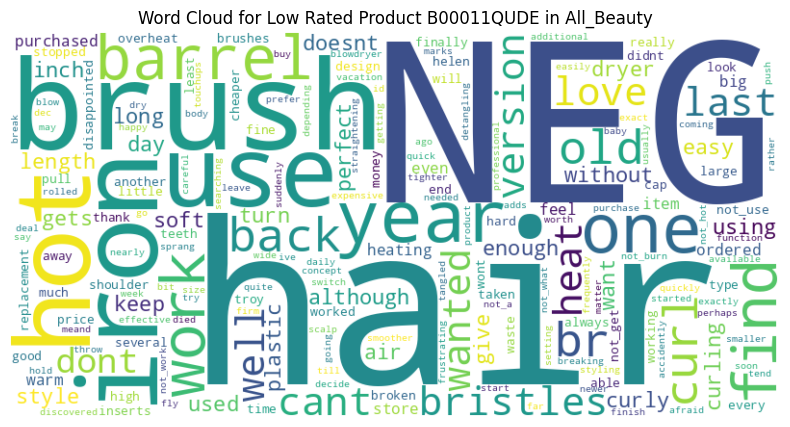


Digital_Music - Products with Many Reviews but Low Ratings:
       product_id  avg_rating  review_count
2790   B000065UHB    2.066667            15
25766  B01BYANS6W    2.843750            32
26562  B01IWEQYIM    2.809524            21


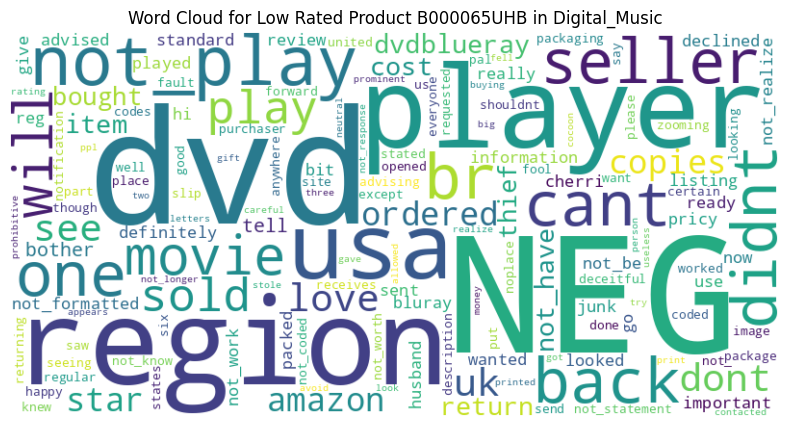


Video_Games - Products with Many Reviews but Low Ratings:
      product_id  avg_rating  review_count
1900  B000FKBCX4    2.052632            19
6575  B007FTE2VW    1.583333            24
6663  B007VTVRFA    1.526316            19
8652  B00IAVDQCK    3.000000            16
9972  B00W8FYF56    2.636364            11


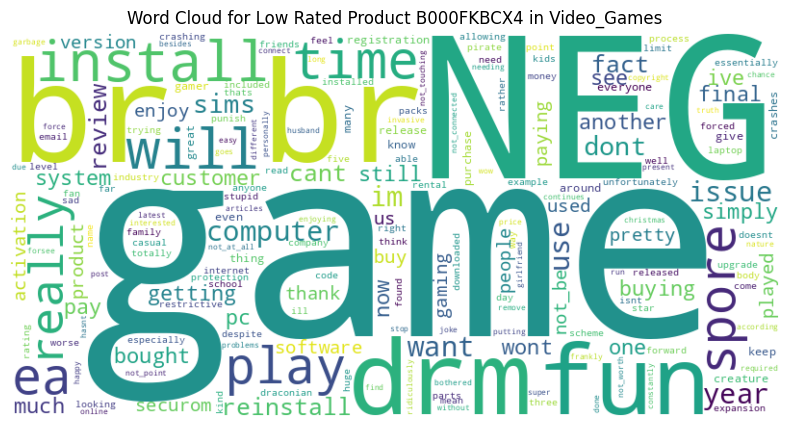


Handmade_Products - Products with Many Reviews but Low Ratings:
       product_id  avg_rating  review_count
23677  B07ZSH8MC2    2.900000            10
26497  B08FHS3537    2.857143            21
26782  B08HPQHQ98    2.600000            10


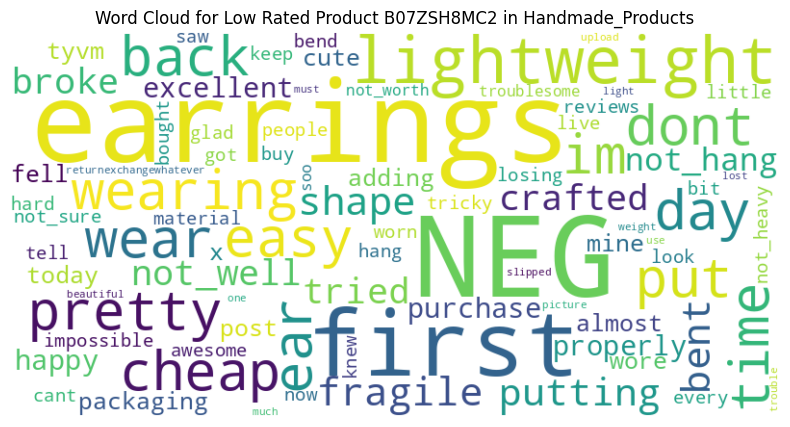


Health_and_Personal_Care - Products with Many Reviews but Low Ratings:
      product_id  avg_rating  review_count
266   B000I5UARK    3.000000            10
425   B000UX2JSI    1.956522            23
3319  B00JVC1G9C    2.916667            12
4035  B00RA88R1Y    2.571429            14
4726  B00ZWS4B1O    2.533333            15


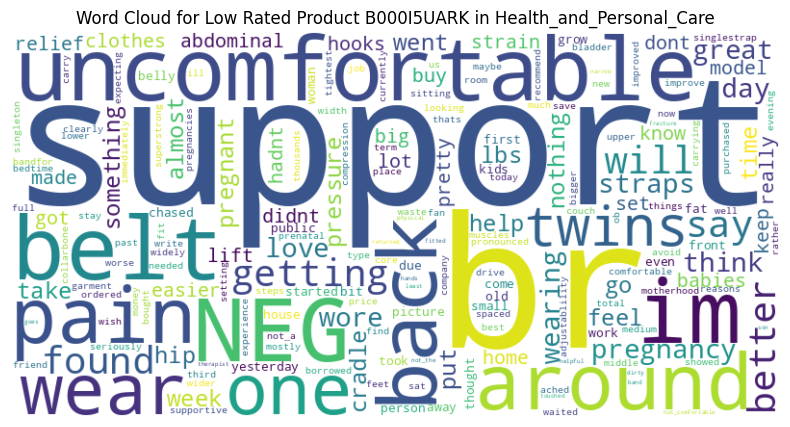

In [9]:
for category, data in cleaned_data.items():
    df = data['reviews']
    grouped = df.groupby('asin').agg({
        'rating': ['mean', 'count'],
        'text': lambda x: ' '.join(x)
    }).reset_index()
    grouped.columns = ['product_id', 'avg_rating', 'review_count', 'all_text']
    low_rated = grouped[(grouped['avg_rating'] <= 3.0) & (grouped['review_count'] >= 10)]

    print(f"\n{category} - Products with Many Reviews but Low Ratings:")
    print(low_rated[['product_id', 'avg_rating', 'review_count']].head())

    for _, row in low_rated.head(1).iterrows():
        wordcloud = WordCloud(width=800, height=400, background_color='white').generate(row['all_text'])
        plt.figure(figsize=(10, 5))
        plt.imshow(wordcloud, interpolation='bilinear')
        plt.axis('off')
        plt.title(f'Word Cloud for Low Rated Product {row["product_id"]} in {category}')
        plt.show()


Displaying Metadata for Top 5 Best-Selling Products in Each Category

In [10]:
for category, data in cleaned_data.items():
    df = data['reviews']
    top_products = df['asin'].value_counts().head(5)
    print(f"\n {category} - Top 5 Best-Selling Products:")
    print(top_products)

    top_product_ids = top_products.index.tolist()
    top_meta = data['meta'][data['meta']['parent_asin'].isin(top_product_ids)]
    print(top_meta[['parent_asin', 'title', 'store', 'features']])


 All_Beauty - Top 5 Best-Selling Products:
asin
B007IAE5WY    173
B00EEN2HCS    120
B00R1TAN7I    114
B0107QYW14    108
B00YQ6X8EO    100
Name: count, dtype: int64
      parent_asin                                              title  \
26020  B00R1TAN7I  GranNaturals Boar Bristle Smoothing Hair Brush...   
29624  B00YQ6X8EO  Herbivore - Natural Sea Mist Texturizing Salt ...   

              store                                           features  
26020  GranNaturals  ['REDUCE FRIZZ: As you brush, oils from your h...  
29624     HERBIVORE                                                 []  

 Digital_Music - Top 5 Best-Selling Products:
asin
5559166928    138
B00003CXKT    112
B0000041CD     98
B001EJH4SW     95
B014QI0FI8     87
Name: count, dtype: int64
      parent_asin                                              title  \
1253   5559166928  Elvis Presley - He Touched Me The Gospel Music...   
25878  B00003CXKT                                 Test Big Data 1737   
26246  B001EJH4

Plotting Smoothed Monthly Average Rating Trends for Each Product Category


 All_Beauty Date Range: 2001-03-05 07:27:57 to 2023-03-21 00:44:31.712000
year_month
2001-03      1
2002-12      1
2003-02      1
2003-03      1
2003-04      1
          ... 
2022-11    269
2022-12    253
2023-01    251
2023-02    191
2023-03    133
Freq: M, Name: count, Length: 226, dtype: int64


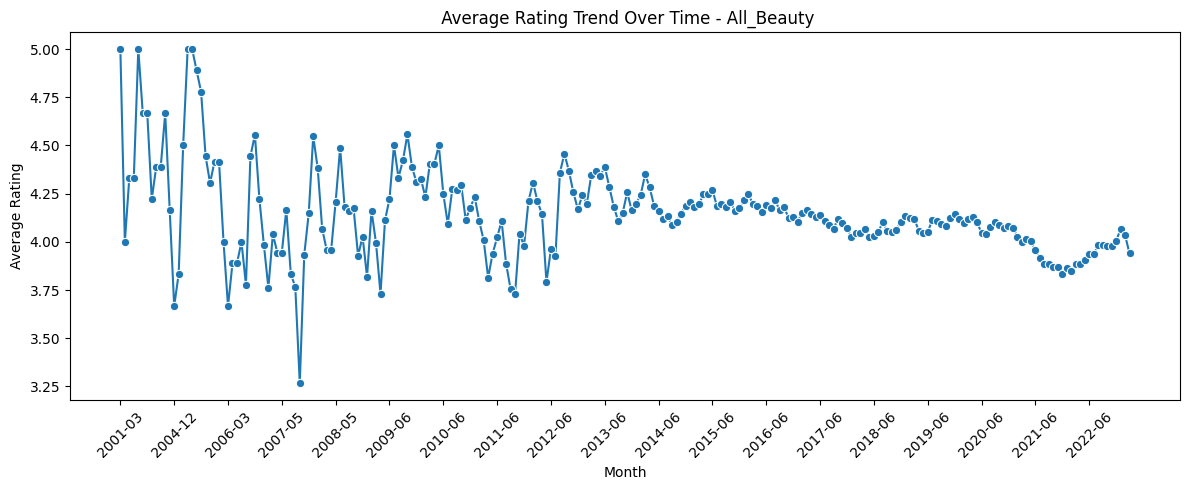


 Digital_Music Date Range: 1998-07-31 06:43:31 to 2023-04-15 16:29:53.916000
year_month
1998-07      1
1998-08      1
1998-09      2
1998-10      1
1998-11      2
          ... 
2022-12    401
2023-01    414
2023-02    303
2023-03    318
2023-04     41
Freq: M, Name: count, Length: 291, dtype: int64


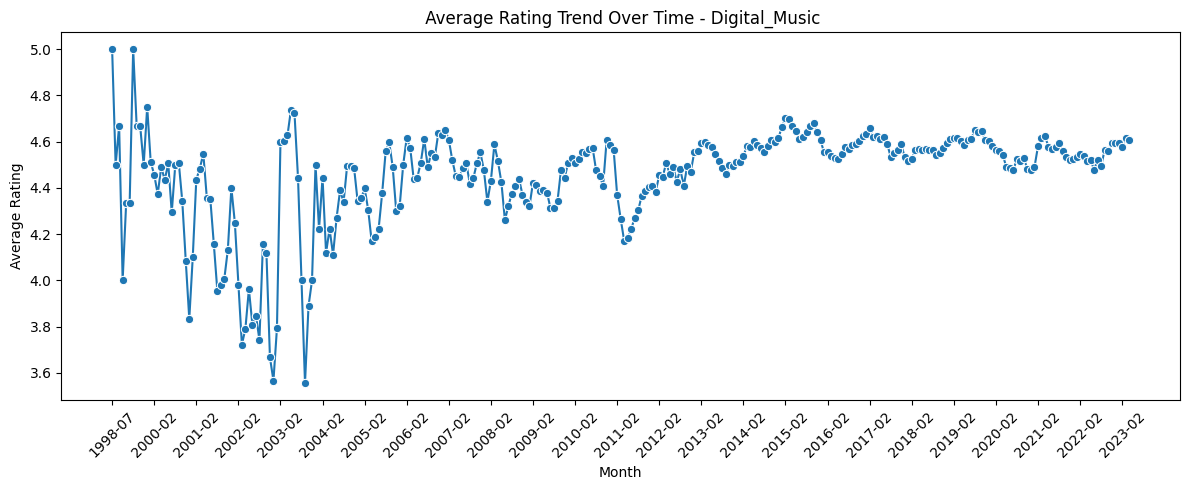


 Video_Games Date Range: 1999-11-15 19:19:36 to 2023-03-18 23:09:42.098000
year_month
1999-11      1
1999-12      1
2000-01      1
2000-02      2
2000-05      4
          ... 
2022-11    367
2022-12    445
2023-01    441
2023-02    304
2023-03    211
Freq: M, Name: count, Length: 277, dtype: int64


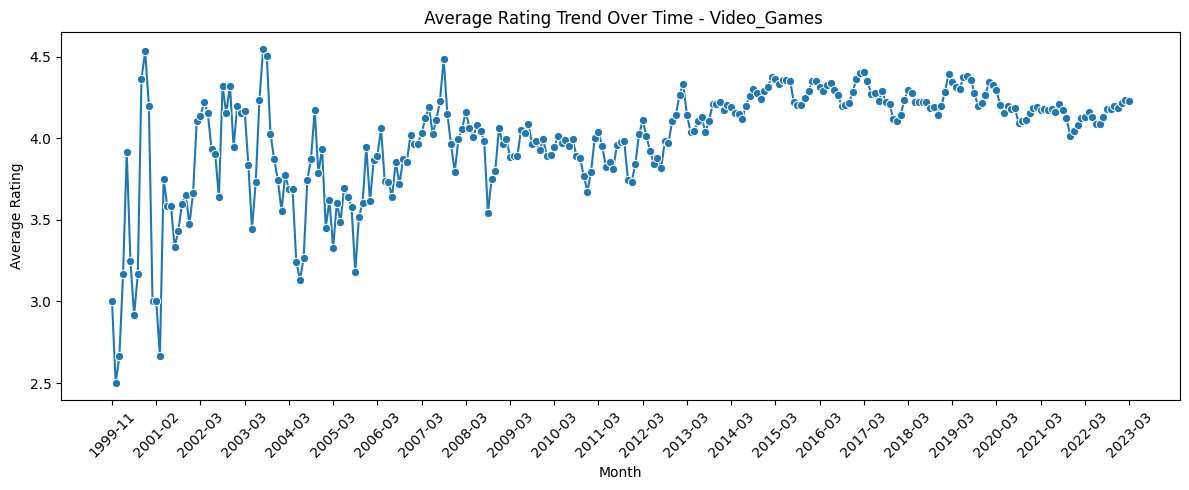


 Handmade_Products Date Range: 2013-02-12 19:10:29 to 2023-03-23 13:11:59.630000
year_month
2013-02       1
2013-06       1
2013-07       1
2013-12       1
2014-04       1
           ... 
2022-11     795
2022-12    1080
2023-01     938
2023-02     699
2023-03     534
Freq: M, Name: count, Length: 99, dtype: int64


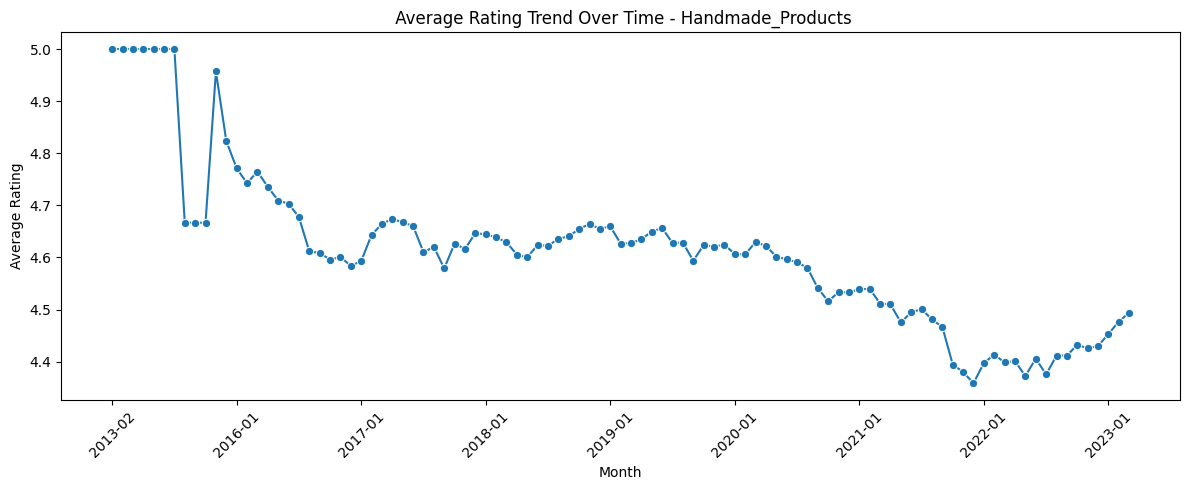


 Health_and_Personal_Care Date Range: 2002-06-14 09:33:36 to 2023-03-22 20:24:30.998000
year_month
2002-06      1
2004-08      1
2005-02      1
2005-05      2
2005-06      1
          ... 
2022-11    312
2022-12    276
2023-01    277
2023-02    208
2023-03    167
Freq: M, Name: count, Length: 209, dtype: int64


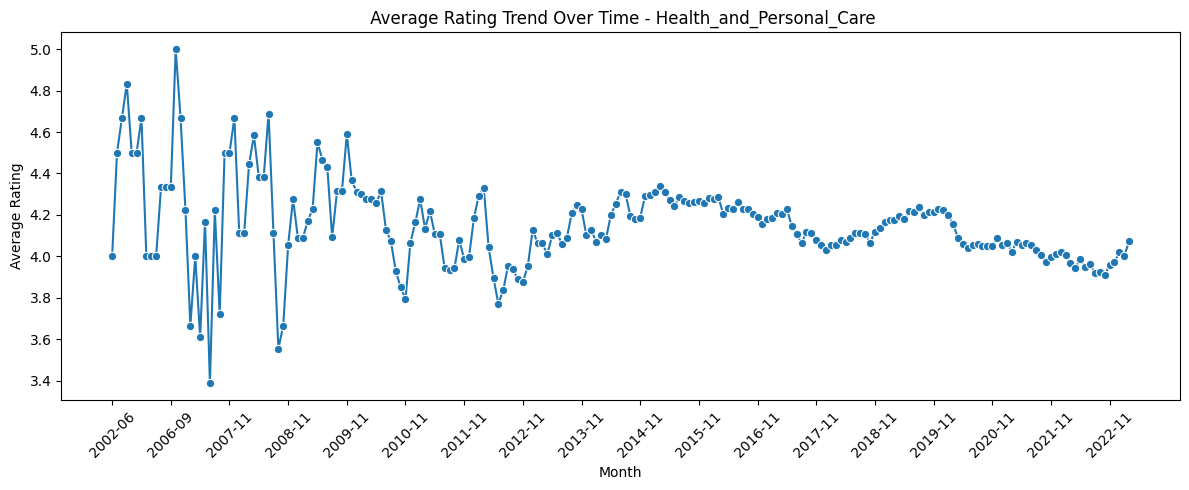

In [60]:
for category, data in cleaned_data.items():
    df = data['reviews'].copy()

    df['timestamp'] = pd.to_numeric(df['timestamp'], errors='coerce')
    df = df.dropna(subset=['timestamp'])
    df['timestamp'] = pd.to_datetime(df['timestamp'], unit='ms', errors='coerce')

    df = df.dropna(subset=['timestamp'])
    df['year_month'] = df['timestamp'].dt.to_period('M')

    print(f"\n {category} Date Range: {df['timestamp'].min()} to {df['timestamp'].max()}")
    print(df['year_month'].value_counts().sort_index())

    trend = df.groupby('year_month')['rating'].mean().reset_index()
    trend['avg_rating_smooth'] = trend['rating'].rolling(window=3, min_periods=1).mean()
    trend['year_month'] = trend['year_month'].astype(str)


    plt.figure(figsize=(12, 5))
    sns.lineplot(data=trend, x='year_month', y='avg_rating_smooth', marker='o')
    plt.title(f' Average Rating Trend Over Time - {category}')
    plt.xlabel('Month')
    plt.ylabel('Average Rating')

    # Show fewer x-axis labels (e.g., every 12th)
    xticks_to_show = trend['year_month'][::12]  # one per year
    plt.xticks(ticks=range(0, len(trend), 12), labels=xticks_to_show, rotation=45)

    plt.tight_layout()
    plt.show()

In [62]:
# We use DistilBERT because it offers a good balance between accuracy and speed,
# making it ideal for large-scale review datasets.
# Compared to RoBERTa or full BERT, DistilBERT is about 40% smaller and about 60% faster,
# with only a minor loss in performance  about 2%.
# VADER doesn't perform well on complex, full-length reviews.

from datasets import Dataset

# sentiment analysis pipeline
sentiment_model = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english",
    tokenizer="distilbert-base-uncased-finetuned-sst-2-english",
    truncation=True, #truncation enabled
    max_length=512,
    device=0  # GPU needed
)

# Helper function to convert Hugging Face labels into signed scores
def label_to_score(label, score):
    return score if label == "POSITIVE" else -score

RUN_SENTIMENT = True  # Set to True only when you want to run it

# Only run this block if RUN_SENTIMENT is True
if RUN_SENTIMENT:
    for category in category_dict.keys():
        print(f"\n Sentiment Analysis for: {category.upper()}")

        df_clean_reviews = cleaned_data[category]["reviews"].copy()
        
        # Hugging Face Dataset (requires text column)
        dataset = Dataset.from_pandas(df_clean_reviews[['text']])
        
        # Apply sentiment model in batches
        results = sentiment_model(dataset['text'], batch_size=64, truncation=True)

        # Convert labels to scores
        sentiment_scores = [label_to_score(r['label'], r['score']) for r in results]

        # Save back to original DataFrame
        df_clean_reviews['sentiment_score'] = sentiment_scores
        df_clean_reviews['rating_norm'] = (df_clean_reviews['rating'] - 1) / 4

        # Weighted average of model sentiment and rating
        w1, w2 = 0.8, 0.2
        df_clean_reviews['final_sentiment'] = (
            w1 * df_clean_reviews['sentiment_score'] +
            w2 * df_clean_reviews['rating_norm']
        )

        # Store results back
        cleaned_data[category]["reviews"] = df_clean_reviews

        # Show preview
        print(df_clean_reviews[['text', 'rating', 'sentiment_score', 'rating_norm', 'final_sentiment']].head())

Device set to use cuda:0



 Sentiment Analysis for: ALL_BEAUTY
                                                text  rating  sentiment_score  \
0  this spray is really nice . it smells really g...     5.0         0.992963   
1  this product does what i need it to do , i jus...     4.0        -0.998541   
2                        smells good , feels great !     5.0         0.999872   
3                                     felt synthetic     1.0        -0.998915   
4                                            love it     5.0         0.999875   

   rating_norm  final_sentiment  
0         1.00         0.994371  
1         0.75        -0.648833  
2         1.00         0.999898  
3         0.00        -0.799132  
4         1.00         0.999900  

 Sentiment Analysis for: DIGITAL_MUSIC
                                                text  rating  sentiment_score  \
0  if i had a dollar for how many times i have pl...     5.0         0.999098   
1  awesome sound cant wait to see them in person ...     5.0         0

Feature Engineering – Price & Rating
This cell processes product metadata to extract two key features:

unit_price: Price per unit (e.g. per ml, tablet, pack), extracted using regex from title/description.

norm_weighted_rating: A weighted rating that accounts for the number of reviews.

Only entries with non-negative price and average_rating are used.
The result is a cleaner dataset for value-based product comparisons.

In [70]:
from IPython.display import display

for category in cleaned_data.keys():
    print(f"\n[Processing category: {category.upper()}]")

    # Load the product metadata for the current category
    df = cleaned_data[category]["meta"].copy()

    # Convert key fields to numeric format
    df["average_rating"] = pd.to_numeric(df.get("average_rating"), errors="coerce")
    df["rating_number"] = pd.to_numeric(df.get("rating_number"), errors="coerce")
    df["price"] = pd.to_numeric(df.get("price"), errors="coerce")

    # Create a filtered copy for processing, keeping only valid values
    df_copy = df[(df["price"] >= 0) & (df["average_rating"] >= 0)].copy()

    # Compute normalized weighted rating
    df_copy["norm_weighted_rating"] = df_copy["average_rating"] * np.log1p(df_copy["rating_number"])

    # Preprocess text fields
    for col in ["title", "description"]:
        if col in df_copy.columns:
            df_copy[col] = df_copy[col].apply(lambda x: " ".join(x) if isinstance(x, list) else str(x))

    # Quantity extraction from title/description
    quantity_regex = r"(?i)(\d+(?:\.\d+)?)\s*(ml|g|kg|l|oz|pack|pcs|tablet|inch|sheet|bottle|count|unit)s?\b"
    df_copy["approx_quantity"] = np.nan
    df_copy["unit_type"] = pd.Series([None] * len(df_copy), dtype="object")

    for col in ["title", "description"]:
        if col not in df_copy.columns:
            continue
        matches = df_copy[col].str.extract(quantity_regex)
        quantity = pd.to_numeric(matches[0], errors="coerce")
        units = matches[1]

        fill_mask = df_copy["approx_quantity"].isna() & quantity.notna()
        df_copy.loc[fill_mask, "approx_quantity"] = quantity[fill_mask]
        df_copy.loc[fill_mask, "unit_type"] = units[fill_mask]

    # Default quantity = 1 if no value extracted
    df_copy["approx_quantity"] = df_copy["approx_quantity"].fillna(1)

    # Calculate unit price
    df_copy["unit_price"] = df_copy["price"] / df_copy["approx_quantity"]
    df_copy["unit_price"] = df_copy["unit_price"].replace([np.inf, -np.inf], np.nan)

    # Preview sample of results
    print("\nSample of engineered meta features (Top 5):")
    sample = df_copy[[
        "title", "price", "approx_quantity", "unit_type",
        "unit_price", "average_rating", "rating_number", "norm_weighted_rating"
    ]].dropna().head(5).copy()

    sample["title"] = sample["title"].str.slice(0, 70) + "..."
    num_cols = ["price", "approx_quantity", "unit_price", "average_rating", "norm_weighted_rating"]
    sample[num_cols] = sample[num_cols].apply(lambda col: col.round(3))

    display(sample)


[Processing category: ALL_BEAUTY]

Sample of engineered meta features (Top 5):


,title,price,approx_quantity,unit_type,unit_price,average_rating,rating_number,norm_weighted_rating
5,Lurrose 100Pcs Full Cover Fake Toenails Artifi...,6.99,100.0,Pcs,0.070,3.7,35,13.259
8,Gold extatic Musk EDT 90ml...,86.95,90.0,ml,0.966,3.7,2,4.065
29,"Garnier Fructis Color Sealer, Instant, Lightwe...",24.00,6.0,oz,4.000,4.4,17,12.718
32,"Enjoy VOLUMIZING ELIXIR, Style (with Sleek Ste...",22.49,8.8,oz,2.556,5.0,1,3.466
37,Sharonelle Natural Cream Soft Wax for Sensitiv...,50.00,14.0,oz,3.571,4.0,1,2.773



[Processing category: DIGITAL_MUSIC]

Sample of engineered meta features (Top 5):


,title,price,approx_quantity,unit_type,unit_price,average_rating,rating_number,norm_weighted_rating
680,Original Album Series (5 Pack) by Todd Rundgre...,108.99,5.0,Pack,21.798,5.0,2,5.493
1604,Break My Heart [12 INCH VINYL SINGLE]...,18.00,12.0,INCH,1.500,4.0,1,2.773
1932,TWICE FANCY YOU 7th Mini Album [B] Ver CD+POST...,28.99,10.0,pcs,2.899,4.7,196,24.831
2948,DAWN FM THE DISTANCE TEE Size S Explicit...,65.68,6.0,OZ,10.947,5.0,10,11.989
3313,DAWN FM ACCEPT YOUR FATE TEE Size XL Exp...,66.68,6.0,OZ,11.113,5.0,31,17.329



[Processing category: VIDEO_GAMES]

Sample of engineered meta features (Top 5):


,title,price,approx_quantity,unit_type,unit_price,average_rating,rating_number,norm_weighted_rating
52,"Fpxnb 4 Pairs Switch Thumb Grip Set, Analog St...",8.99,8.00,Pcs,1.124,4.5,150,22.578
72,DLseego Devil Rabbit Switch Protective Case So...,16.99,4.00,PCS,4.248,4.7,46,18.096
76,Silicone Analog Controller Thumb Stick Grips C...,5.86,2.00,PCS,2.930,4.5,1249,32.089
118,"Hwasubun Gaming Mouse Pads,2 Pack (Color Desig...",49.99,2.00,Pack,24.995,4.6,91,20.800
152,"Redragon K503 PC Gaming Keyboard, Wired, Multi...",31.99,25.15,oz,1.272,4.6,472,28.332



[Processing category: HANDMADE_PRODUCTS]

Sample of engineered meta features (Top 5):


,title,price,approx_quantity,unit_type,unit_price,average_rating,rating_number,norm_weighted_rating
16,"Looped Wooden Bead Garland Decor, 2Pcs Farmhou...",6.59,2.0,Pcs,3.295,4.7,10,11.270
18,Shungite children stretchy bracelet...,11.99,5.0,g,2.398,3.3,18,9.717
33,Handmade Coffee Stud Earrings...,12.95,316.0,L,0.041,4.6,35,16.484
41,Blue Tiger's Eye Cabochon Stone Necklace - Cho...,34.99,1.0,inch,34.990,5.0,3,6.931
43,"Taco Badge Reel, Funny Taco Badge Reel, Food B...",13.95,33.0,inch,0.423,4.9,67,20.676



[Processing category: HEALTH_AND_PERSONAL_CARE]

Sample of engineered meta features (Top 5):


,title,price,approx_quantity,unit_type,unit_price,average_rating,rating_number,norm_weighted_rating
14,uxcell Rubber Shoes Boots Heels Sole Repair Pl...,8.99,4.0,Pcs,2.248,4.0,10,9.592
23,Bath and Body Works 3 Pack Holiday's Favorites...,49.99,3.0,Pack,16.663,4.3,6,8.367
25,"Major Senna-Lax 8.6 mg Sennosides, 100 Tablets...",42.19,100.0,Tablet,0.422,4.7,2,5.163
32,"Naturade Probiotics 30 B CFU Capsules, 30 Coun...",24.99,30.0,Count,0.833,3.9,13,10.292
68,"Electronic Foot File Pedicure Tools, Electric ...",20.20,250.0,g,0.081,3.0,15,8.318


PART B

TASK 1

Product Clustering Summary
We cluster Amazon products using both text and numeric data:

Text processing: Titles and descriptions are cleaned and combined.
Feature extraction: TF-IDF (unigrams + bigrams) and normalized price/rating are used.
Clustering: KMeans is applied for k = 2 to 10. The best k is chosen via Silhouette Score.
Visualization: Truncated SVD projects the clusters to 2D.
Analysis: For each cluster, we show the average price, rating, and a few sample products.

This method reveals product groupings based on content and value.


 Processing category: All_Beauty
TF-IDF matrix shape: (3584, 5000)
 Numeric features shape: (3584, 2)
 Final combined feature matrix shape: (3584, 5002)

Silhouette scores for k from 2 to 10:
k=2: Silhouette Score = 0.3965
k=3: Silhouette Score = 0.4004
k=4: Silhouette Score = 0.1867
k=5: Silhouette Score = 0.1907
k=6: Silhouette Score = 0.1072
k=7: Silhouette Score = 0.1178
k=8: Silhouette Score = 0.0977
k=9: Silhouette Score = 0.0915
k=10: Silhouette Score = 0.1177


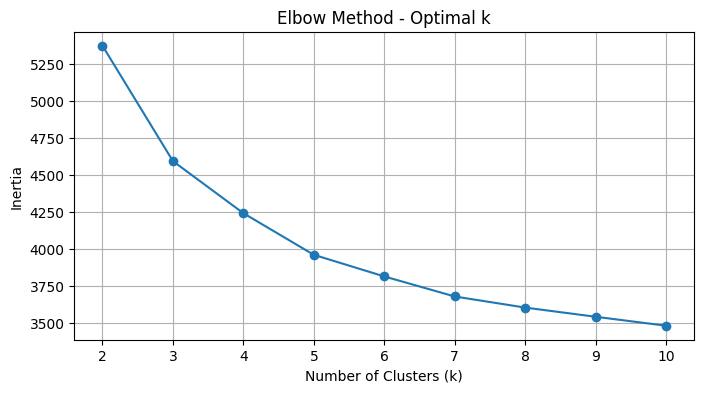

Silhouette Score (k=3): 0.4004


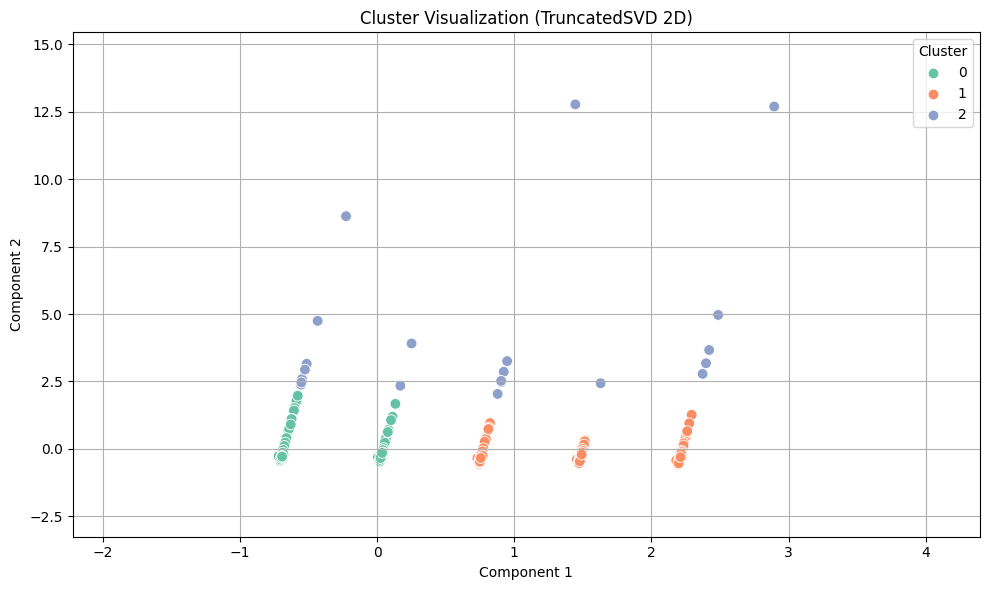

cluster
0    2849
1     693
2      42
Name: count, dtype: int64

Cluster Statistics:
         rating   price  num_products
cluster                              
0          4.84   17.92          2849
1          1.92   17.00           693
2          4.05  249.07            42

Cluster 0 Sample Products:


,title_y,rating,price
2,"New Road Beauty - Creamsicle - Variety 3 Pack Paraffin Wax - Peach, Vanilla & Mango - Moisturize and Smooths Skin - Nourishing and Provides Massage Therapy",5.000000,21.980000
24,"4 Point Eyebrow Pen, Micro Ink Tat Brow Pen Waterproof Eyebrow Pencil With Micro-Fork Tips for Daily Natural Eye Brown Makeup (Dark Brown/ Chestnut)",5.000000,7.990000
37,"Shower Cap - Blue Dot Pattern, Vinyl material, elastic band, extra large, large, won’t fall off your head,",4.000000,4.080000



Cluster 1 Sample Products:


,title_y,rating,price
186,Salux Nylon Japanese Beauty Skin Bath Wash Cloth/towel (3) Blue Yellow and Pink,3.000000,12.990000
263,Taya Beauty Inner Core Hair Strong Anti-Breakage Shampoo & Conditioner Duo - Strengthening and Repairing Formula - Free From Sulfates and Parabens - 8 fl oz Bottles,1.000000,48.000000
363,Versace Yellow Diamond Perfumed Deodorant Stick 50ml/1.7oz,1.000000,25.990000



Cluster 2 Sample Products:


,title_y,rating,price
3240,Shaving Factory Blade Dispenser,5.000000,477.060000
4033,Tom Ford Private Blend Tuscan Leather 3.4 oz / 100ml,5.000000,273.380000
4601,"Skinlastin Buy 2 - Best Age Defying Anti Wrinkle Anti Aging Cream Powerful Gentle Formula of Advanced Peptide Technology, Antioxidant Hydrating Moisturizers Promotes Younger More Vibrant Looking Skin",5.000000,149.990000



 Processing category: Digital_Music
TF-IDF matrix shape: (18017, 5000)
 Numeric features shape: (18017, 2)
 Final combined feature matrix shape: (18017, 5002)

Silhouette scores for k from 2 to 10:
k=2: Silhouette Score = 0.4815
k=3: Silhouette Score = 0.4932
k=4: Silhouette Score = 0.4293
k=5: Silhouette Score = 0.2738
k=6: Silhouette Score = 0.2208
k=7: Silhouette Score = 0.1861
k=8: Silhouette Score = 0.0789
k=9: Silhouette Score = 0.0744
k=10: Silhouette Score = 0.0710


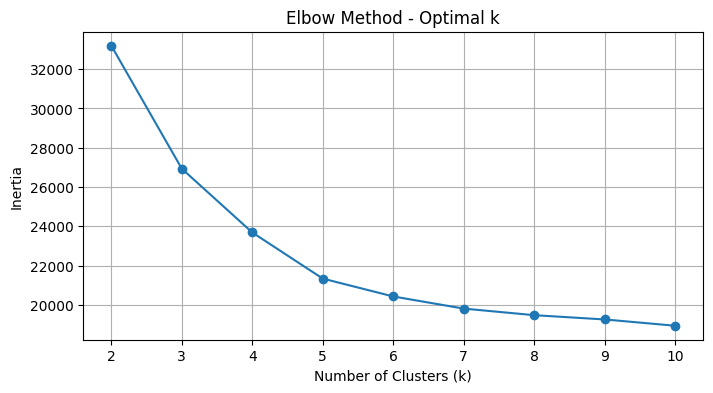

Silhouette Score (k=3): 0.4932


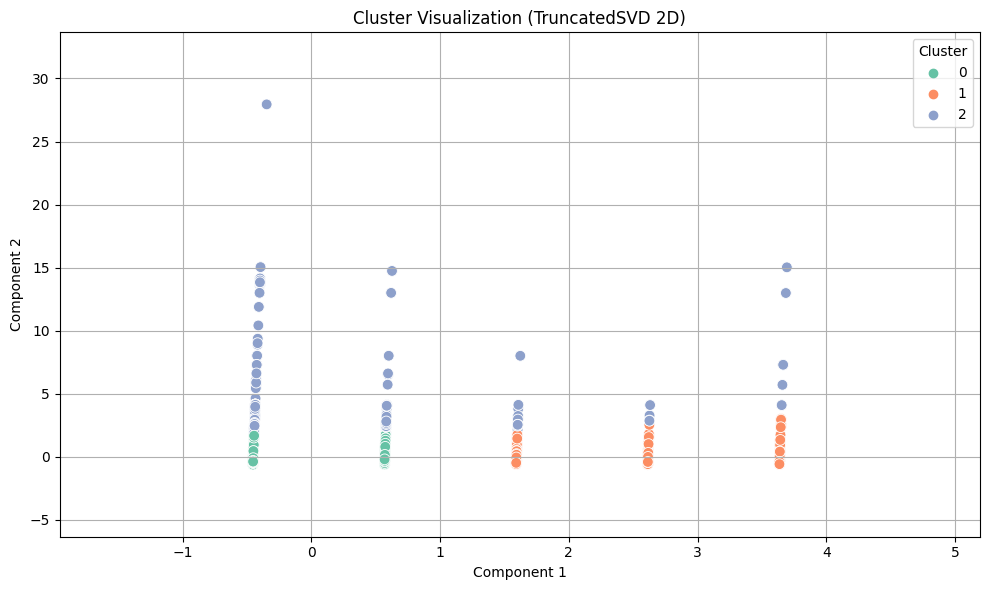

cluster
0    15663
1     1985
2      369
Name: count, dtype: int64

Cluster Statistics:
         rating   price  num_products
cluster                              
0          4.88   24.43         15663
1          2.14   25.11          1985
2          4.69  289.93           369

Cluster 0 Sample Products:


,title_y,rating,price
6,RE-DUNN,5.000000,20.000000
7,Goodbye Yellow Brick Road (CD),5.000000,12.690000
8,Fulfillingness' First Finale (CD),5.000000,15.060000



Cluster 1 Sample Products:


,title_y,rating,price
4,GOSSIP PARTY! -THE BEST OF CELEB HITS R&B N HOUSE MIX- MIXED BY DJ D.LOCK,3.000000,3.880000
22,The Chicago Story: Complete Greatest Hits,3.000000,22.940000
23,Runnin' Down a Dream: A Tribute to Tom Petty,3.000000,12.980000



Cluster 2 Sample Products:


,title_y,rating,price
39,Soul Show,5.000000,296.010000
87,The Sound of Spring,5.000000,204.000000
129,The Four Tops & The Temptations (2 CD Boxed Set),5.000000,300.000000



 Processing category: Video_Games
TF-IDF matrix shape: (16464, 5000)
 Numeric features shape: (16464, 2)
 Final combined feature matrix shape: (16464, 5002)

Silhouette scores for k from 2 to 10:
k=2: Silhouette Score = 0.5716
k=3: Silhouette Score = 0.3899
k=4: Silhouette Score = 0.3903
k=5: Silhouette Score = 0.2035
k=6: Silhouette Score = 0.2069
k=7: Silhouette Score = 0.2042
k=8: Silhouette Score = 0.1469
k=9: Silhouette Score = 0.1335
k=10: Silhouette Score = 0.0909


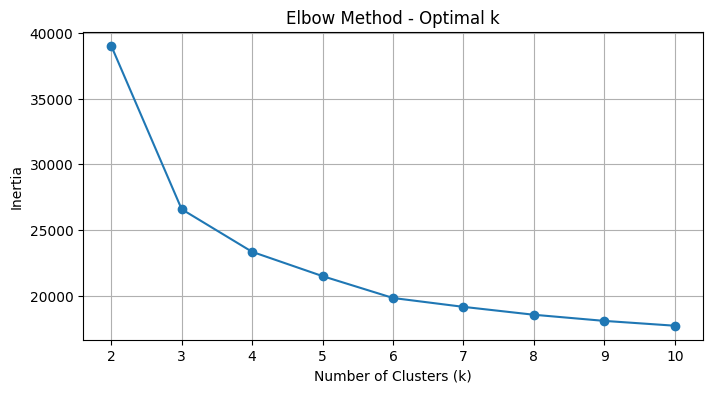

Silhouette Score (k=2): 0.5716


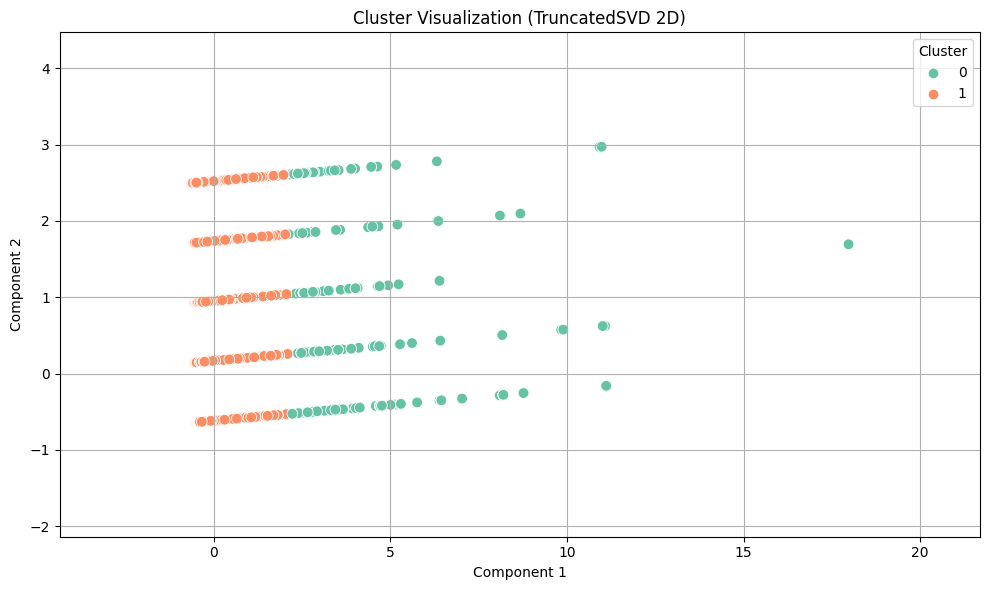

cluster
1    15701
0      763
Name: count, dtype: int64

Cluster Statistics:
         rating   price  num_products
cluster                              
0          4.33  412.91           763
1          4.25   45.23         15701

Cluster 0 Sample Products:


,title_y,rating,price
27,Nintendo 3DS XL - Blue/Black [Old Model] Games Included,5.000000,264.950000
139,"Arcade 1Up Golden Tee Classic Arcade with Riser, 5ft",5.000000,499.990000
232,PlayStation 4 Slim 500GB Console [Discontinued],5.000000,359.000000



Cluster 1 Sample Products:


,title_y,rating,price
1,Final Fantasy VII: Remake - PlayStation 4,5.000000,25.950000
2,Sid Meier’s Civilization VI: Rise and Fall [Online Game Code][Mac] [Online Game Code],5.000000,29.990000
3,PowerA Enhanced Wireless Controller for Nintendo Switch - Mario Silhouette,5.000000,67.610000



 Processing category: Handmade_Products
TF-IDF matrix shape: (11670, 5000)
 Numeric features shape: (11670, 2)
 Final combined feature matrix shape: (11670, 5002)

Silhouette scores for k from 2 to 10:
k=2: Silhouette Score = 0.4982
k=3: Silhouette Score = 0.5003
k=4: Silhouette Score = 0.2738
k=5: Silhouette Score = 0.2705
k=6: Silhouette Score = 0.1628
k=7: Silhouette Score = 0.1531
k=8: Silhouette Score = 0.0814
k=9: Silhouette Score = 0.0620
k=10: Silhouette Score = 0.0560


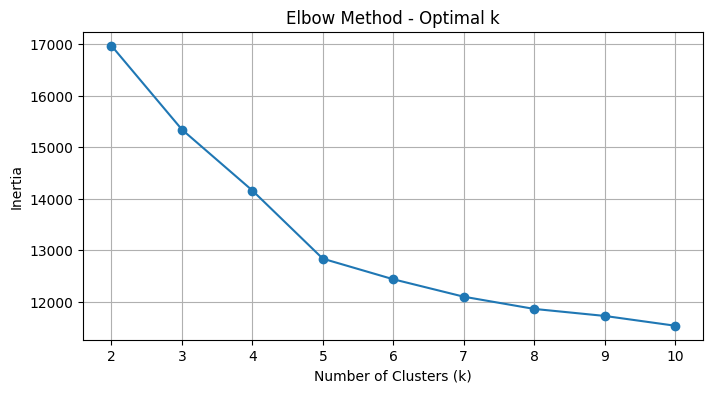

Silhouette Score (k=3): 0.5003


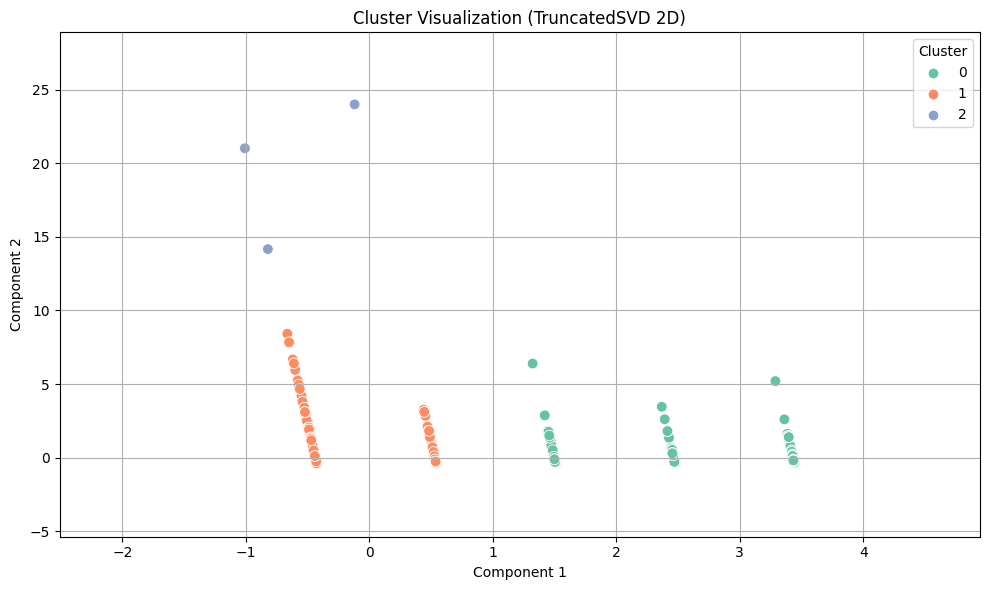

cluster
1    10170
0     1496
2        4
Name: count, dtype: int64

Cluster Statistics:
         rating    price  num_products
cluster                               
0          2.03    25.13          1496
1          4.91    28.08         10170
2          4.75  1427.25             4

Cluster 0 Sample Products:


,title_y,rating,price
87,YouClean - 17 oz Fizzy Foaming Bath Salt - Handcrafted in California - Epsom Salt & Mediterranean Sea Salt - Muscle Relaxants (Watermelonade),3.000000,17.830000
95,Genuine Blue Star Sapphire Sterling Silver 925 Ring,1.000000,118.780000
97,Sterling Silver Bar Necklace - Designer Handmade Horizontal Small Stick Jewelry - 16 inch + 2 inch,2.000000,40.000000



Cluster 1 Sample Products:


,title_y,rating,price
3,"Sterling Silver Moon Phase Charm Necklace, 18""",5.000000,24.000000
16,"Artisan Tiny Blue Forget Me Not Real Dry Pressed Flower Pendant Necklace for Women - Handmade Jewelry Made in USA,",5.000000,39.950000
17,"Free Mom Hugs Sticker, Laptop Sticker, Water Bottle Sticker, Phone Sticker, Window Sticker, Pride Sticker, LGBT Sticker",5.000000,2.990000



Cluster 2 Sample Products:


,title_y,rating,price
995,1 carat Diamond solitaire Engagement Ring for women 14K Yellow Gold,4.000000,1700.000000
5689,"The Elevation Pedestal | Raises Your Washer & Dryer | Custom-Made to Fit All Machines, Samsung, LG, GE, Whirlpool, etc| Adds Storage, Beautifies Your Laundry Room | Premium, Solid Wood, 52-58” Wide",5.000000,1495.000000
19177,"8"" Thickness Water Green Velvet Floor Seating, Sectional Sofa, Velvet Floor Sofa, Bohemian Sectionals, Arabic Floor Sofa Set, Floor Couches (Sofa Full Set)",5.000000,1019.000000



 Processing category: Health_and_Personal_Care
TF-IDF matrix shape: (9755, 5000)
 Numeric features shape: (9755, 2)
 Final combined feature matrix shape: (9755, 5002)

Silhouette scores for k from 2 to 10:
k=2: Silhouette Score = 0.4113
k=3: Silhouette Score = 0.1969
k=4: Silhouette Score = 0.1983
k=5: Silhouette Score = 0.1624
k=6: Silhouette Score = 0.0820
k=7: Silhouette Score = 0.0941
k=8: Silhouette Score = 0.0725
k=9: Silhouette Score = 0.0917
k=10: Silhouette Score = 0.0943


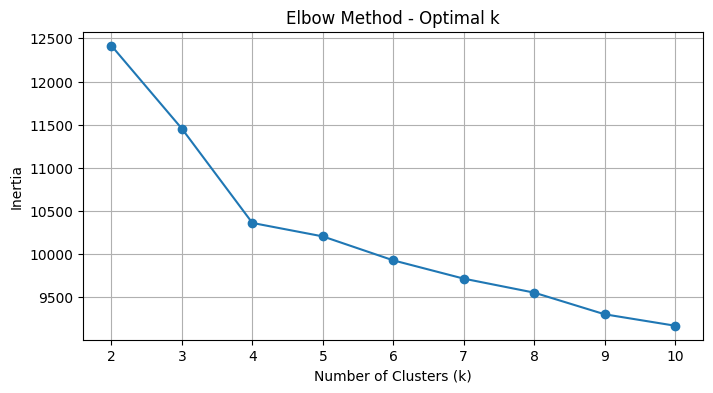

Silhouette Score (k=2): 0.4113


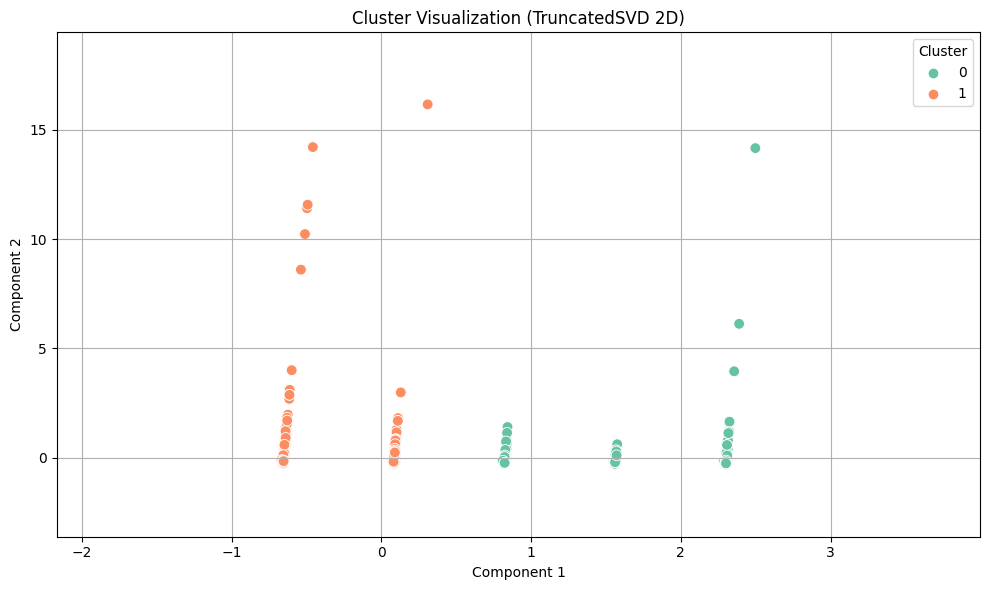

cluster
1    7833
0    1922
Name: count, dtype: int64

Cluster Statistics:
         rating  price  num_products
cluster                             
0          1.95  27.62          1922
1          4.85  29.08          7833

Cluster 0 Sample Products:


,title_y,rating,price
21,"Gold Bond No Mess Talc-Free Body Powder Spray, 7 oz., Classic Scent, With a Triple Action Formula",1.000000,24.990000
59,"Flushable Wipes for Baby and Kids by Kandoo, Unscented for Sensitive Skin, Hypoallergenic Potty Training Wet Cleansing Cloths, 42 Count, Pack of 12",1.000000,22.680000
158,Puffs Plus Lotion Facial Tissue (Old),3.000000,26.990000



Cluster 1 Sample Products:


,title_y,rating,price
13,"Super Organics Amla (Amalaki) Powder | Organic Superfood Powder | Raw Superfoods | Whole Food Supplement | Good Vitamin C Content – Vegan, Non-GMO & Gluten-Free, 8 oz",4.000000,7.400000
14,"Amazon Elements Women’s One Daily Multivitamin, 59% Whole Food Cultured, Vegan, 65 Tablets, 2 month supply (Packaging may vary)",5.000000,31.660000
17,North American Walker Tray with Non-Slip Grip Mat,5.000000,26.900000


In [61]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import TruncatedSVD
from scipy.sparse import hstack

# Loop through each product category
for category_name, sources in category_dict.items():
    print(f"\n Processing category: {category_name}")

    # Get cleaned review and metadata DataFrames
    df_clean_reviews = cleaned_data[category_name]["reviews"]
    df_clean_meta = cleaned_data[category_name]["meta"]

    # Merge reviews with metadata based on 'parent_asin'
    merged_df = pd.merge(df_clean_reviews, df_clean_meta, on="parent_asin", how="left")

    # Keep only rows with non-negative prices and ratings
    merged_df = merged_df[(merged_df["price"] >= 0) & (merged_df["rating"] >= 0)]


    # Clean the 'description' column
    def preprocess_description_column(df):
        df = df.copy()
        df['description'] = df['description'].fillna('').apply(lambda x: ' '.join(x) if isinstance(x, list) else str(x))
        df['description_clean'] = df['description'].apply(preprocess_text)
        df = df[df['description_clean'].str.strip() != '']
        return df

    # Clean the 'title_y' (from metadata) column
    def preprocess_title_column(df):
        df = df.copy()
        df['title_y'] = df['title_y'].fillna('').apply(lambda x: ' '.join(x) if isinstance(x, list) else str(x))
        df['title_y_clean'] = df['title_y'].apply(preprocess_text)
        df = df[df['title_y_clean'].str.strip() != '']
        return df

    # Apply preprocessing
    merged_df = preprocess_description_column(merged_df)
    merged_df = preprocess_title_column(merged_df)

    # Combine title and description text
    merged_df["combined_text"] = (
        merged_df["title_y_clean"].fillna('') + " " + merged_df["description_clean"].fillna('')
    )

    # TF-IDF vectorization
    tfidf = TfidfVectorizer(
        max_df=0.9,
        min_df=3,
        max_features=5000,
        ngram_range=(1, 2),
        sublinear_tf=True
    )
    tfidf_matrix = tfidf.fit_transform(merged_df["combined_text"])

    # Use price and rating as numeric features
    numeric_features = merged_df[['normalized_price', 'normalized_rating']].values

    # Combine text and numeric features
    feature_matrix = hstack([tfidf_matrix, numeric_features])

    # Print matrix shapes for debugging
    print(f"TF-IDF matrix shape: {tfidf_matrix.shape}")
    print(f" Numeric features shape: {numeric_features.shape}")
    print(f" Final combined feature matrix shape: {feature_matrix.shape}")

    # Try different values of k for KMeans
    inertia = []
    silhouette_scores = []
    k_values = list(range(2, 11))

    print("\nSilhouette scores for k from 2 to 10:")
    for k in k_values:
        model = KMeans(n_clusters=k, random_state=42)
        labels = model.fit_predict(feature_matrix)
        inertia.append(model.inertia_)
        score = silhouette_score(feature_matrix, labels)
        silhouette_scores.append(score)
        print(f"k={k}: Silhouette Score = {score:.4f}")

    # Elbow plot to help determine optimal k
    plt.figure(figsize=(8, 4))
    plt.plot(k_values, inertia, marker='o')
    plt.title("Elbow Method - Optimal k")
    plt.xlabel("Number of Clusters (k)")
    plt.ylabel("Inertia")
    plt.grid(True)
    plt.show()

    # Choose the best k based on silhouette score
    optimal_k_index = np.argmax(silhouette_scores)
    optimal_k = k_values[optimal_k_index]
    kmeans = KMeans(n_clusters=optimal_k, random_state=42)
    cluster_labels = kmeans.fit_predict(feature_matrix)

    # Print final silhouette score
    score = silhouette_score(feature_matrix, cluster_labels)
    print(f"Silhouette Score (k={optimal_k}): {score:.4f}")

    # Reduce dimensions using TruncatedSVD (PCA for sparse matrices)
    reduced = TruncatedSVD(n_components=2, random_state=42).fit_transform(feature_matrix)

    # Create a DataFrame for visualization
    svd_df = pd.DataFrame(reduced, columns=["SVD1", "SVD2"])
    svd_df["Cluster"] = cluster_labels

    # Calculate padding for a cleaner plot
    pad_percent = 0.2
    min_pad = 1.5
    x_min, x_max = svd_df["SVD1"].min(), svd_df["SVD1"].max()
    y_min, y_max = svd_df["SVD2"].min(), svd_df["SVD2"].max()
    x_pad = max((x_max - x_min) * pad_percent, min_pad)
    y_pad = max((y_max - y_min) * pad_percent, min_pad)

    # Plot 2D cluster visualization
    plt.figure(figsize=(10, 6))
    sns.scatterplot(data=svd_df, x="SVD1", y="SVD2", hue="Cluster", palette="Set2", s=60)
    plt.title("Cluster Visualization (TruncatedSVD 2D)")
    plt.xlabel("Component 1")
    plt.ylabel("Component 2")
    plt.xlim(x_min - x_pad, x_max + x_pad)
    plt.ylim(y_min - y_pad, y_max + y_pad)
    plt.legend(title="Cluster")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Assign cluster labels to the original data
    merged_df["cluster"] = cluster_labels

    # Print number of items per cluster
    print(merged_df['cluster'].value_counts())

    # === Cluster Statistics Summary ===
    cluster_stats = merged_df.groupby("cluster").agg({
        "rating": "mean",
        "price": "mean",
        "title_y": "count"
    }).rename(columns={"title_y": "num_products"})

    print("\nCluster Statistics:")
    print(cluster_stats.round(2))

    # === Show Sample Products per Cluster ===
    for cluster_id in sorted(merged_df["cluster"].unique()):
        print(f"\nCluster {cluster_id} Sample Products:")
        sample = merged_df[merged_df["cluster"] == cluster_id][["title_y", "rating", "price"]].head(3)
        display(sample.style.set_properties(**{'text-align': 'left'}))

TASK 2

- Collaborative Filtering: User-Based and Item-Based Recommendations

Construct a user-item interaction matrix from filtered Amazon product reviews.

Get Cosine similarity is used to compute similarity scores between users and between items.

Get the Top recommended products for a sample user based on both methods.


In [25]:
from sklearn.metrics.pairwise import cosine_similarity

# User-Based Collaborative Filtering Prediction
def predict_user_based(user_id, asin, K=5):
    # If user/item not present, return NaN
    if asin not in user_item_matrix.columns or user_id not in user_item_matrix.index:
        return np.nan
        
    # Get top K similar users
    similar_users = user_similarity_df[user_id].sort_values(ascending=False)[1:K+1]
    user_ratings = user_item_matrix.loc[similar_users.index, asin]
    weighted_sum = np.dot(similar_users.values, user_ratings.values)
    similarity_sum = np.sum(similar_users.values)
    return weighted_sum / similarity_sum if similarity_sum != 0 else 0

# Item-Based Collaborative Filtering Prediction
def predict_item_based(user_id, asin, K=5):
    if asin not in item_item_matrix.index or user_id not in user_item_matrix.index:
        return np.nan

    # If user/item not present, return NaN
    similar_items = item_similarity_df[asin].sort_values(ascending=False)[1:K+1]
    item_ratings = user_item_matrix.loc[user_id, similar_items.index]
    weighted_sum = np.dot(similar_items.values, item_ratings.values)
    similarity_sum = np.sum(similar_items.values)
    return weighted_sum / similarity_sum if similarity_sum != 0 else 0

# Load data
category = 'All_Beauty'
df_reviews = cleaned_data[category]['reviews'].copy()
df_meta = cleaned_data[category]['meta'].copy()

# Focus only on necessary columns
df_reviews = df_reviews[['user_id', 'asin', 'rating', 'text']]
df_meta = df_meta[['parent_asin', 'price', 'main_category']]

# Filter out invalid prices/ratings
df_meta = df_meta[df_meta['price'] >= 0]
df_reviews = df_reviews[df_reviews['rating'] >= 0]

# Normalize price
scaler = MinMaxScaler()
df_meta['price'] = scaler.fit_transform(df_meta[['price']])

# If needed: Clean and combine text fields
df_reviews['text_clean'] = df_reviews['text']  # Preprocessed text
df_reviews['combined_clean'] = df_reviews['text_clean']  # If you want to use it later

# Filter frequent users and items
top_users = df_reviews['user_id'].value_counts().head(10000).index
top_items = df_reviews['asin'].value_counts().head(10000).index
df_filtered = df_reviews[df_reviews['user_id'].isin(top_users) & df_reviews['asin'].isin(top_items)]

# Build user-item matrix
user_item_matrix = df_filtered.pivot_table(index='user_id', columns='asin', values='rating').fillna(0)
print(f"Filtered User-Item Matrix Shape: {user_item_matrix.shape}")

# Compute similarities between users
user_similarity = cosine_similarity(user_item_matrix)
user_similarity_df = pd.DataFrame(user_similarity, index=user_item_matrix.index, columns=user_item_matrix.index)

# Compute similarities between items
item_item_matrix = user_item_matrix.T
item_similarity = cosine_similarity(item_item_matrix)
item_similarity_df = pd.DataFrame(item_similarity, index=item_item_matrix.index, columns=item_item_matrix.index)

# === USER-BASED CF ===
example_user = user_item_matrix.index[898]
user_cf_recommendations = []

for asin in user_item_matrix.columns:
    score = predict_user_based(example_user, asin)
    user_cf_recommendations.append((asin, score))

# Get top 10 recommendations
top_user_cf = sorted(user_cf_recommendations, key=lambda x: x[1], reverse=True)[:10]
user_cf_df = pd.DataFrame(top_user_cf, columns=['asin', 'predicted_rating'])
user_cf_df = user_cf_df[user_cf_df['predicted_rating'] > 0]

print(f"\nTop User-Based CF Recommendations for User {example_user}:")
print(user_cf_df[['asin', 'predicted_rating']])

# === ITEM-BASED CF ===
item_cf_recommendations = []
for asin in user_item_matrix.columns:
    score = predict_item_based(example_user, asin)
    item_cf_recommendations.append((asin, score))

# Get top 10 recommendations
top_item_cf = sorted(item_cf_recommendations, key=lambda x: x[1], reverse=True)[:10]
item_cf_df = pd.DataFrame(top_item_cf, columns=['asin', 'predicted_rating'])
item_cf_df = item_cf_df[item_cf_df['predicted_rating'] > 0]

print(f"\nTop Item-Based CF Recommendations for User {example_user}:")
print(item_cf_df[['asin', 'predicted_rating']])


Filtered User-Item Matrix Shape: (8775, 7589)

Top User-Based CF Recommendations for User AEGZE2CDVM3R4LVB3EVGDWV77UOQ:
         asin  predicted_rating
0  B01G1F7HAS          3.176471
1  B01MQTDH4J          1.176471

Top Item-Based CF Recommendations for User AEGZE2CDVM3R4LVB3EVGDWV77UOQ:
         asin  predicted_rating
0  B01MQTDH4J          3.000000
1  B01G1F7HAS          2.524893
2  B015RR870U          0.503465
3  B01MRX18Y5          0.331939


- Content-Based Filtering Using Word2Vec:

Each product's user review text is converted into a vector using a pretrained Word2Vec model.

The average word embeddings for each product form a content feature matrix.

Cosine similarity is computed across these vectors to identify similar products.

For a selected product, the top 5 most similar items are recommended based on their content features.


In [44]:
# Convert product text into vector representation using Word2Vec model
def get_text_vector(text, model):
    words = nltk.word_tokenize(text.lower())
    words = [w for w in words if w in model.key_to_index]
    if not words:
        return np.zeros(model.vector_size)
    return np.mean([model[w] for w in words], axis=0)

# Recommend similar products using content-based filtering
def recommend_content_based(asin, K=5):
    if asin not in content_similarity_df.index:
        return []
    similar_items = content_similarity_df[asin].sort_values(ascending=False)[1:K+1]
    return similar_items.index.tolist()

# Get unique product IDs
asin_list = df_reviews['asin'].unique()
content_vectors = []
valid_asins = []

# Build vector representations for each product based on cleaned text
for asin in asin_list:
    combined_text = ' '.join(df_reviews[df_reviews['asin'] == asin]['combined_clean'])
    if not combined_text.strip():
        continue
    vec = get_text_vector(combined_text, w2v_model)
    content_vectors.append(vec)
    valid_asins.append(asin)  # Keep only ASINs with valid vectors

# Create a DataFrame with content-based features
content_feature_df = pd.DataFrame(content_vectors, index=valid_asins)

# Compute similarities between all product vectors
content_similarity = cosine_similarity(content_feature_df)
content_similarity_df = pd.DataFrame(content_similarity, index=valid_asins, columns=valid_asins)


# Generate top 5 recommendations using content-based filtering
example_asin = user_item_matrix.columns[76]  # pick any product as the reference

cbf_recommendations = recommend_content_based(example_asin, K=5)

print(f"Top 5 Content-Based Recommendations similar to Product {example_asin}:")
for similar_asin in cbf_recommendations:
    similarity_score = content_similarity_df.loc[example_asin, similar_asin]
    print(f"ASIN: {similar_asin}, Similarity Score: {similarity_score:.3f}")



Top 5 Content-Based Recommendations similar to Product B000G8LWZI:
ASIN: B01GOINCUQ, Similarity Score: 0.999
ASIN: B007IAM4YU, Similarity Score: 0.999
ASIN: B01NB1ZBA1, Similarity Score: 0.999
ASIN: B01MDTVZTZ, Similarity Score: 0.999
ASIN: B00AD3O3RU, Similarity Score: 0.999


- Hybrid Recommendation System (Collaborative + Content-Based)
 
Collaborative Filtering (CF): Based on item-item similarity and user ratings.

Content-Based Filtering (CBF): Based on the similarity of product descriptions (from review text).

Each product is scored as a weighted average of CF and CBF scores, 70% and 30%, accordingly.

Recommendations for the Top products for a specific user and the Top-N recommendations for multiple users.


In [30]:

# Hybrid recommendation combining collaborative filtering and content-based filtering
def hybrid_score(user_id, asin, cf_weight=0.7, cbf_weight=0.3, K=5):
    # Compute item-based collaborative filtering score
    cf_score = predict_item_based(user_id, asin, K)

    # Initialize content-based filtering (CBF) score
    cbf_score = 0
    if user_id in user_item_matrix.index and asin in content_similarity_df.index:
        # Get items the user has already rated
        user_rated_items = user_item_matrix.loc[user_id].dropna()
        user_rated_items = user_rated_items[user_rated_items > 0]  

        # Calculate average content similarity to rated items
        similarities = [
            content_similarity_df.loc[asin, other_asin]
            for other_asin in user_rated_items.index
            if other_asin in content_similarity_df.columns
        ]

        if similarities:
            cbf_score = np.mean(similarities)

    # Normalize collaborative filtering score to [0, 1] range if needed
    if not np.isnan(cf_score) and cf_score > 1:
      cf_score = cf_score / 5.0  # Normalize to [0–1]

    # Final hybrid score is a weighted combination of CF and CBF
    return (cf_score * cf_weight + cbf_score * cbf_weight) *5.0

    

# === SINGLE USER RECOMMENDATION EXAMPLE ===
example_user = user_item_matrix.index[898]
recommendations = []
for asin in user_item_matrix.columns:
    score = hybrid_score(example_user, asin)
    recommendations.append((asin, score))

top_recommendations = sorted(recommendations, key=lambda x: x[1], reverse=True)[:5]

print(f"Top 5 Hybrid Recommendations for User {example_user}:")
for asin, score in top_recommendations:
    print(f"ASIN: {asin}, Hybrid Score: {score:.3f}")

# === MULTI-USER RECOMMENDATION LOOP ===
num_users = 10   # number of users to generate recommendations for
top_n = 5     # number of top recommendations per user

# Select N users from the matrix
selected_users = user_item_matrix.index[890: 890 + num_users]

for user_id in selected_users:
    recommendations = []
    # Compute hybrid score for each item
    for asin in user_item_matrix.columns:
        score = hybrid_score(user_id, asin)
        recommendations.append((asin, score))

    # Select top-N recommended items
    top_recommendations = sorted(recommendations, key=lambda x: x[1], reverse=True)[:top_n]

    print(f"\nTop {top_n} Hybrid Recommendations for User {user_id}:")
    for asin, score in top_recommendations:
        print(f"ASIN: {asin}, Hybrid Score: {score:.3f}")


Top 10 Hybrid Recommendations for User AEGZE2CDVM3R4LVB3EVGDWV77UOQ:
ASIN: B01MQTDH4J, Hybrid Score: 3.594
ASIN: B01G1F7HAS, Hybrid Score: 3.262
ASIN: B015RR870U, Hybrid Score: 3.253
ASIN: B01MRX18Y5, Hybrid Score: 2.653
ASIN: B00RPJZMUM, Hybrid Score: 1.494

Top 5 Hybrid Recommendations for User AEGU7DBZORBQULZMRB5KBTYIDHYA:
ASIN: B00LGORG7Y, Hybrid Score: 1.500
ASIN: B08BL85TKP, Hybrid Score: 1.495
ASIN: B0811S3MZ2, Hybrid Score: 1.495
ASIN: B088637DF9, Hybrid Score: 1.495
ASIN: B07DQ6NG1H, Hybrid Score: 1.494

Top 5 Hybrid Recommendations for User AEGURW5ZOBLTCOTBWO4T5EEXMYHQ:
ASIN: B07BSCL33X, Hybrid Score: 4.993
ASIN: B09RZFRLMS, Hybrid Score: 4.980
ASIN: B07PLFY2DL, Hybrid Score: 4.480
ASIN: B005FGR5K2, Hybrid Score: 2.704
ASIN: B019C5KXFA, Hybrid Score: 2.250

Top 5 Hybrid Recommendations for User AEGWMCKOPMYKFCBJGYG4O24USIWQ:
ASIN: B00P7CODZ4, Hybrid Score: 4.982
ASIN: B07TKZVF2F, Hybrid Score: 4.956
ASIN: B081N8WY8N, Hybrid Score: 4.944
ASIN: B0814SCPGC, Hybrid Score: 4.718
AS

TASK 3

- Sentiment Labeling from Review Ratings
Prepare review data for sentiment analysis:

Extract only the text and rating fields from the cleaned video game reviews.

Sentiment labels are generated based on rating thresholds: labeled as positive, neutral, negative.

The resulting sentiment distribution gives an overview of user opinion across the dataset.


In [45]:
#Get clean data and keep the review text and rating
video_games_reviews_clean = cleaned_data["Video_Games"]["reviews"]

video_games_reviews = video_games_reviews_clean[['text', 'rating']]

# Create sentiment labels based on normalized rating
def label_sentiment(rating):
    if rating <= 2:
        return "negative"
    elif rating <= 3.5:
        return "neutral"
    else:
        return "positive"

# Make a copy to avoid modifying the original DataFrame
video_games_reviews = video_games_reviews.copy()

# Apply sentiment labeling to the reviews
video_games_reviews['sentiment_label'] = video_games_reviews['rating'].apply(label_sentiment)


# Print count of each sentiment class
print(video_games_reviews['sentiment_label'].value_counts())

sentiment_label
positive    39395
negative     6635
neutral      3970
Name: count, dtype: int64


In [46]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
    max_features=10000,
    stop_words='english',
    min_df= 2,
    max_df= 0.8,
    ngram_range=(1, 2)
)

# Fit and transform cleaned text
X_tfidf = tfidf_vectorizer.fit_transform(video_games_reviews['text'])

# Define the target labels
y = video_games_reviews['sentiment_label']

# Preview shapes
print("TF-IDF shape:", X_tfidf.shape)
print("Target shape:", y.shape)



TF-IDF shape: (50000, 10000)
Target shape: (50000,)


In [47]:
import os

# We have downloaded in Kaggle the FastText model we are using 
os.listdir('/kaggle/input/fasttext-crawl-300d-2m')

from gensim.models import KeyedVectors
# Path to the vector file
vec_path = '/kaggle/input/fasttext-crawl-300d-2m/crawl-300d-2M.vec'

# Load model 
fasttext_model = KeyedVectors.load_word2vec_format(vec_path, binary=False)


- Generate Review Embeddings Using FastText:
Each review is vectorized by averaging the FastText word embeddings of its tokens.
The result is a 300-dimensional vector per review.
These embeddings will be used as input features for classification models.
The target variable remains as the sentiment label.


In [48]:
# Convert each review to vector by averaging word vectors
def fasttext_vectorize(text, model, dim=300):
    tokens = text.split()  # whitespace tokenization
    valid_vectors = [model[word] for word in tokens if word in model]

    # Return mean vector if any valid tokens found; else return zero vector
    if valid_vectors:
        return np.mean(valid_vectors, axis=0)
    else:
        return np.zeros(dim)

# Create the feature matrix by vectorizing each review
X_fasttext = np.vstack(
    video_games_reviews['text'].apply(lambda x: fasttext_vectorize(x, fasttext_model)).values
)

# Define target variable as sentiment labels
y = video_games_reviews['sentiment_label']

# Confirm shape
print("FastText feature matrix shape:", X_fasttext.shape)


FastText feature matrix shape: (50000, 300)


Evaluate three machine learning models using TF-IDF features and 10-fold cross-validation:
- Multinomial Naive Bayes
- K-Nearest Neighbors (KNN).
- Random Forest
  
Each model is evaluated using:
- Accuracy
- Precision 
- Recall 
- F1-score


In [49]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score

# Define evaluation metrics for cross-validation
scoring = {
    'accuracy': make_scorer(accuracy_score),
    'precision': make_scorer(precision_score, average='macro', zero_division=0),
    'recall': make_scorer(recall_score, average='macro', zero_division=0),
    'f1': make_scorer(f1_score, average='macro', zero_division=0)
}

# Store results in dictionary for TF-IDF
model_results = {}

# === Multinomial Naive Bayes ===
nb_model = MultinomialNB()
nb_scores = cross_validate(nb_model, X_tfidf, y, cv=10, scoring=scoring)
model_results['Naive Bayes'] = nb_scores

# === K-Nearest Neighbors (KNN) ===
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_scores = cross_validate(knn_model, X_tfidf, y, cv=10, scoring=scoring)
model_results['KNN'] = knn_scores

# === Random Forest Classifier ===
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_scores = cross_validate(rf_model, X_tfidf, y, cv=10, scoring=scoring)
model_results['Random Forest'] = rf_scores


In [50]:
from tabulate import tabulate

# Prepare a results table for TF-IDF models
tfidf_table = []
for model_name, scores in model_results.items():
    tfidf_table.append([
        model_name,
        f"{scores['test_precision'].mean():.4f}",
        f"{scores['test_recall'].mean():.4f}",
        f"{scores['test_f1'].mean():.4f}",
        f"{scores['test_accuracy'].mean():.4f}"
    ])

# Define column headers
headers = ["TF-IDF", "Precision", "Recall", "F1-Score", "Accuracy"]
# Display results
print(tabulate(tfidf_table, headers=headers, tablefmt="github"))


| TF-IDF        |   Precision |   Recall |   F1-Score |   Accuracy |
|---------------|-------------|----------|------------|------------|
| Naive Bayes   |      0.6644 |   0.4902 |     0.5138 |     0.8411 |
| KNN           |      0.6252 |   0.3674 |     0.3588 |     0.7985 |
| Random Forest |      0.6553 |   0.4924 |     0.5091 |     0.8406 |


Evaluate three machine learning models using Fast Text features and 10-fold cross-validation:
- Gaussian Naive Bayes
- K-Nearest Neighbors (KNN).
- Random Forest

Using same evaluation metrics as before

In [51]:
from sklearn.naive_bayes import GaussianNB

# Store results in dictionary for FastText
fasttext_results = {}

# === Gaussian Naive Bayes ===
gnb_model = GaussianNB()
gnb_scores = cross_validate(gnb_model, X_fasttext, y, cv=10, scoring=scoring)
fasttext_results['Naive Bayes (Gaussian)'] = gnb_scores

# === K-Nearest Neighbors ===
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_scores = cross_validate(knn_model, X_fasttext, y, cv=10, scoring=scoring)
fasttext_results['KNN'] = knn_scores

# === Random Forest ===
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_scores = cross_validate(rf_model, X_fasttext, y, cv=10, scoring=scoring)
fasttext_results['Random Forest'] = rf_scores


In [56]:
# Prepare a results table for models trained on FastText features
fasttext_table = []
for model_name, scores in fasttext_results.items():
    fasttext_table.append([
        model_name,
        f"{scores['test_precision'].mean():.4f}",
        f"{scores['test_recall'].mean():.4f}",
        f"{scores['test_f1'].mean():.4f}",
        f"{scores['test_accuracy'].mean():.4f}"
    ])

# Define column headers
headers = ["EMBEDDINGS", "Precision", "Recall", "F1-Score", "Accuracy"]
# Display Results
print(tabulate(fasttext_table, headers=headers, tablefmt="github"))


| EMBEDDINGS             |   Precision |   Recall |   F1-Score |   Accuracy |
|------------------------|-------------|----------|------------|------------|
| Naive Bayes (Gaussian) |      0.389  |   0.4269 |     0.2939 |     0.3787 |
| KNN                    |      0.535  |   0.4715 |     0.4904 |     0.7966 |
| Random Forest          |      0.6803 |   0.3995 |     0.4067 |     0.8103 |


In [53]:
# Function to extract and format average CV scores for each model
def extract_cv_metrics(cv_scores, model_name, feature_type):
    return {
        'Feature Set': feature_type,
        'Model': model_name,
        'Precision (Macro)': round(cv_scores['test_precision'].mean(), 4),
        'Recall (Macro)': round(cv_scores['test_recall'].mean(), 4),
        'F1-Score (Macro)': round(cv_scores['test_f1'].mean(), 4),
        'Accuracy': round(cv_scores['test_accuracy'].mean(), 4)
      }

# Collect all results into a summary list
summary_rows = []

# Add results from TF-IDF-based models
for model, scores in model_results.items():
    summary_rows.append(extract_cv_metrics(scores, model, "TF-IDF"))

# Add results from FastText embedding-based models
for model, scores in fasttext_results.items():
    summary_rows.append(extract_cv_metrics(scores, model, "EMBEDDINGS"))

# Convert to a DataFrame for tabulation
cv_results_table = pd.DataFrame(summary_rows)

# Define columns
headers = ["Feature Set", "Model", "Precision", "Recall", "F1-Score", "Accuracy"]
# Display results 
print(tabulate(cv_results_table, headers=headers, tablefmt="github"))

|    | Feature Set   | Model                  |   Precision |   Recall |   F1-Score |   Accuracy |
|----|---------------|------------------------|-------------|----------|------------|------------|
|  0 | TF-IDF        | Naive Bayes            |      0.6644 |   0.4902 |     0.5138 |     0.8411 |
|  1 | TF-IDF        | KNN                    |      0.6252 |   0.3674 |     0.3588 |     0.7985 |
|  2 | TF-IDF        | Random Forest          |      0.6553 |   0.4924 |     0.5091 |     0.8406 |
|  3 | EMBEDDINGS    | Naive Bayes (Gaussian) |      0.389  |   0.4269 |     0.2939 |     0.3787 |
|  4 | EMBEDDINGS    | KNN                    |      0.535  |   0.4715 |     0.4904 |     0.7966 |
|  5 | EMBEDDINGS    | Random Forest          |      0.6803 |   0.3995 |     0.4067 |     0.8103 |


Final Test Set Evaluation (TF-IDF)

After cross-validation, we now perform a final test set evaluation using a hold-out split (80% train, 20% test):

- Models are trained on the training portion of the TF-IDF feature set.
- Performance is assessed on unseen data using the same metrics.

In [54]:
from sklearn.model_selection import train_test_split

# === Final Test Evaluation (TF-IDF Feature Set) ===

# Split the data into training and testing sets (80/20)
X_train_tfidf, X_test_tfidf, y_train, y_test = train_test_split(X_tfidf, y, test_size=0.2, random_state=42)

# Store performance results on the test set
test_results_table = []

# === K-Nearest Neighbors ===
knn_model.fit(X_train_tfidf, y_train)
y_pred_knn = knn_model.predict(X_test_tfidf)
test_results_table.append([
    "KNN",
    f"{precision_score(y_test, y_pred_knn, average='macro', zero_division=0):.4f}",
    f"{recall_score(y_test, y_pred_knn, average='macro', zero_division=0):.4f}",
    f"{f1_score(y_test, y_pred_knn, average='macro', zero_division=0):.4f}",
    f"{accuracy_score(y_test, y_pred_knn):.4f}"
])

# === Multinomial Naive Bayes ===
nb_model.fit(X_train_tfidf, y_train)
y_pred_nb = nb_model.predict(X_test_tfidf)
test_results_table.append([
    "Naive Bayes",
    f"{precision_score(y_test, y_pred_nb, average='macro', zero_division=0):.4f}",
    f"{recall_score(y_test, y_pred_nb, average='macro', zero_division=0):.4f}",
    f"{f1_score(y_test, y_pred_nb, average='macro', zero_division=0):.4f}",
    f"{accuracy_score(y_test, y_pred_nb):.4f}"
])

# === Random Forest Classifier ===
rf_model.fit(X_train_tfidf, y_train)
y_pred_rf = rf_model.predict(X_test_tfidf)
test_results_table.append([
    "Random Forest",
    f"{precision_score(y_test, y_pred_rf, average='macro', zero_division=0):.4f}",
    f"{recall_score(y_test, y_pred_rf, average='macro', zero_division=0):.4f}",
    f"{f1_score(y_test, y_pred_rf, average='macro', zero_division=0):.4f}",
    f"{accuracy_score(y_test, y_pred_rf):.4f}"
])

# Display Final Results on Test Set
print("\nFinal Evaluation on Test Set (TF-IDF):")
print(tabulate(test_results_table, headers=["Model", "Precision", "Recall", "F1-Score", "Accuracy"], tablefmt="github"))



Final Evaluation on Test Set (TF-IDF):
| Model         |   Precision |   Recall |   F1-Score |   Accuracy |
|---------------|-------------|----------|------------|------------|
| KNN           |      0.7105 |   0.369  |     0.3617 |     0.7992 |
| Naive Bayes   |      0.692  |   0.4965 |     0.5209 |     0.8443 |
| Random Forest |      0.7492 |   0.4971 |     0.5177 |     0.8417 |


Final Test Set Evaluation (Fast Text)

After cross-validation, we now perform a final test set evaluation using a hold-out split (80% train, 20% test):

- Models are trained on the training portion of the Fast Text feature set.
- Performance is assessed on unseen data using the same metrics.

In [68]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
from tabulate import tabulate

# === Final Test Set Evaluation Using FastText Embeddings ===

# Split the data into training and testing sets (80/20)
X_train_ft, X_test_ft, y_train, y_test = train_test_split(
    X_fasttext, y, test_size=0.2, random_state=42, stratify=y
)

# List to store final test results
fasttext_test_results = []

# === Gaussian Naive Bayes ===
gnb_model = GaussianNB()
gnb_model.fit(X_train_ft, y_train)
y_pred_gnb = gnb_model.predict(X_test_ft)
fasttext_test_results.append([
    "Naive Bayes (Gaussian)",
    f"{precision_score(y_test, y_pred_gnb, average='macro', zero_division=0):.4f}",
    f"{recall_score(y_test, y_pred_gnb, average='macro', zero_division=0):.4f}",
    f"{f1_score(y_test, y_pred_gnb, average='macro', zero_division=0):.4f}",
    f"{accuracy_score(y_test, y_pred_gnb):.4f}"
])

# === K-Nearest Neighbors ===
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_ft, y_train)
y_pred_knn_ft = knn_model.predict(X_test_ft)
fasttext_test_results.append([
    "KNN",
    f"{precision_score(y_test, y_pred_knn_ft, average='macro', zero_division=0):.4f}",
    f"{recall_score(y_test, y_pred_knn_ft, average='macro', zero_division=0):.4f}",
    f"{f1_score(y_test, y_pred_knn_ft, average='macro', zero_division=0):.4f}",
    f"{accuracy_score(y_test, y_pred_knn_ft):.4f}"
])

# === Random Forest ===
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_ft, y_train)
y_pred_rf_ft = rf_model.predict(X_test_ft)
fasttext_test_results.append([
    "Random Forest",
    f"{precision_score(y_test, y_pred_rf_ft, average='macro', zero_division=0):.4f}",
    f"{recall_score(y_test, y_pred_rf_ft, average='macro', zero_division=0):.4f}",
    f"{f1_score(y_test, y_pred_rf_ft, average='macro', zero_division=0):.4f}",
    f"{accuracy_score(y_test, y_pred_rf_ft):.4f}"
])

# Display results
print("\nFinal Evaluation on Test Set (FastText Embeddings):")
print(tabulate(fasttext_test_results, headers=["Model", "Precision", "Recall", "F1-Score", "Accuracy"], tablefmt="github"))



Final Evaluation on Test Set (FastText Embeddings):
| Model                  |   Precision |   Recall |   F1-Score |   Accuracy |
|------------------------|-------------|----------|------------|------------|
| Naive Bayes (Gaussian) |      0.3767 |   0.4084 |     0.2789 |     0.3801 |
| KNN                    |      0.5394 |   0.4784 |     0.4966 |     0.8012 |
| Random Forest          |      0.7819 |   0.407  |     0.4206 |     0.8133 |


Running Apriori on category: Video_Games
 Total valid transactions: 5444
 Frequent itemsets found: 569

 Top Association Rules with Titles (based on Lift):

                                                       If user buys...                                      ...then likely also buys  Support  Confidence   Lift
                                                            B000VTQ3LU                                                    B002I0J51U   0.0009       0.714 324.05
                                                            B002I0J51U                                                    B000VTQ3LU   0.0009       0.417 324.05
                                   Nintendo Nunchuk Controller - White                             Remote Plus, Mario - Nintendo Wii   0.0009       0.385  77.55
                                   Assassin's Creed IV Black Flag - PC                      Call of Duty Ghosts - PS3 [Digital Code]   0.0009       0.208  29.85
                                      

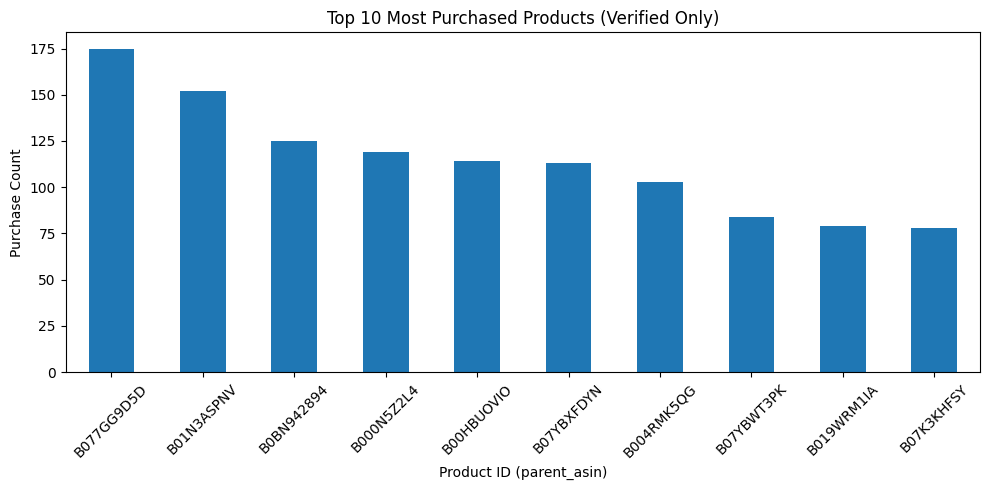

In [10]:
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

# Function to match ASINs to product titles (if available)
def map_asins_to_titles(asins_set):
    titles = meta_titles[meta_titles["parent_asin"].isin(asins_set)]["title"].tolist()
    if titles:
        return ", ".join(titles)
    else:
        return ", ".join(asins_set)  # fallback if no title found

# Define category and load data
category = "Video_Games"
print(f"Running Apriori on category: {category}")

# Load review data and keep only rows with all needed fields
df = cleaned_data[category]["reviews"]
df = df.dropna(subset=["user_id", "parent_asin", "timestamp"]).copy()

# Only keep verified purchases to reduce noise
df = df[df["verified_purchase"] == True]

# Convert timestamp to datetime format
df["timestamp"] = pd.to_numeric(df["timestamp"], errors='coerce')
df = df[(df["timestamp"] > 946684800000) & (df["timestamp"] < 1893456000000)]
df["timestamp"] = pd.to_datetime(df["timestamp"], unit='ms')

# Group products by user and month
df["month"] = df["timestamp"].dt.to_period("M").astype(str)
df["user_month"] = df["user_id"] + "_" + df["month"]
basket = df.groupby("user_month")["parent_asin"].apply(list).reset_index()

# Prepare baskets for Apriori only baskets with >=2 products
transactions = basket["parent_asin"].apply(lambda x: list(set(x))).tolist()
transactions = [t for t in transactions if len(t) >= 2]

print(f" Total valid transactions: {len(transactions)}")

# One-hot encoding of transactions for Apriori
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)
df_encoded = pd.DataFrame(te_array, columns=te.columns_)

# Run Apriori with min_support and limit itemset size
frequent_itemsets = apriori(df_encoded, min_support=0.0009, use_colnames=True, max_len=2)
print(f" Frequent itemsets found: {frequent_itemsets.shape[0]}")

# Generate rules (only with lift ≥ 1.0 and confidence ≥ 0.2)
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)
rules = rules[rules['antecedents'].apply(lambda x: len(x) >= 1) & rules['consequents'].apply(lambda x: len(x) >= 1)]
rules = rules[rules["confidence"] >= 0.2]

# Load metadata to map ASINs to product titles
df_meta = cleaned_data[category]["meta"]
meta_titles = df_meta[["parent_asin", "title"]].dropna().drop_duplicates()

# Add product titles to the rules
rules["antecedent_titles"] = rules["antecedents"].apply(lambda x: map_asins_to_titles(list(x)))
rules["consequent_titles"] = rules["consequents"].apply(lambda x: map_asins_to_titles(list(x)))

#Clean up rules table and round values
rules_display = rules.copy()
rules_display["support"] = rules_display["support"].round(4)
rules_display["confidence"] = rules_display["confidence"].round(3)
rules_display["lift"] = rules_display["lift"].round(2)
rules_display["antecedent_titles"] = rules_display["antecedent_titles"].str.slice(0, 70)
rules_display["consequent_titles"] = rules_display["consequent_titles"].str.slice(0, 70)

# Rename columns for display
rules_display = rules_display.rename(columns={
    "antecedent_titles": "If user buys...",
    "consequent_titles": "...then likely also buys",
    "support": "Support",
    "confidence": "Confidence",
    "lift": "Lift"
})

# Print top rules
final_columns = ["If user buys...", "...then likely also buys", "Support", "Confidence", "Lift"]
print("\n Top Association Rules with Titles (based on Lift):\n")
print(rules_display[final_columns].head(10).to_string(index=False))

# Plot top 10 purchased products
top_items = df["parent_asin"].value_counts().head(10)

plt.figure(figsize=(10, 5))
top_items.plot(kind='bar', title='Top 10 Most Purchased Products (Verified Only)')
plt.xlabel("Product ID (parent_asin)")
plt.ylabel("Purchase Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
